# KSH gazdasági adatok feltáró és területi elemzése

A notebook célja a 2018–2025 közötti vármegyei gazdasági és
munkaerőpiaci folyamatok feltárása, vizualizációja és a területi
gazdasági profilok kialakítása.

Az elemzés Budapestet és a 19 vármegyét tartalmazza. A vizsgált
mutatók közé tartozik a bruttó átlagkereset, a bérnövekedés,
a munkanélküliségi ráta, az álláskeresők száma és a
foglalkoztatottak száma.

A feltáró elemzést hierarchikus klaszterezés követi, amelynek
célja a hasonló gazdasági jellemzőkkel rendelkező területi
egységek azonosítása.

In [1]:
# CSOMAGOK ÉS FÁJLÚTVONALAK

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


BASE_DIR = Path.cwd()
PROCESSED = BASE_DIR / "processed"
FIGURES = BASE_DIR / "figures"

FIGURES.mkdir(
    parents=True,
    exist_ok=True
)

PANEL_FILE = (PROCESSED/ "KSH_Panel_FINAL_2018_2025.csv")

if not PANEL_FILE.exists():

    raise FileNotFoundError(
        "Nem található a végleges paneladatbázis: "
        f"{PANEL_FILE}"
    )

sns.set_theme(
    style="whitegrid"
)

plt.rcParams[
    "figure.figsize"
] = (12, 7)

plt.rcParams[
    "axes.titlesize"
] = 14

plt.rcParams[
    "axes.labelsize"
] = 11

print("Felhasznált adatbázis:",PANEL_FILE)

print("Ábrák mentési helye:",FIGURES)

Felhasznált adatbázis: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\processed\KSH_Panel_FINAL_2018_2025.csv
Ábrák mentési helye: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\figures


In [2]:
# VÉGLEGES PANELADATBÁZIS BETÖLTÉSE

df_panel = pd.read_csv(
    PANEL_FILE,
    encoding="utf-8-sig",
    parse_dates=[
        "Dátum",
        "Cél_Dátum"
    ]
)

df_panel = (
    df_panel
    .sort_values(
        [
            "Dátum",
            "Területi egység neve"
        ]
    )
    .reset_index(drop=True)
)

# BETÖLTÉS UTÁNI ELLENŐRZÉSEK

assert df_panel.shape == (
    640,
    15
)

assert (
    df_panel["Dátum"].nunique()
    == 32
)

assert (
    df_panel[
        "Területi egység neve"
    ].nunique()
    == 20
)

assert not df_panel.duplicated(
    [
        "Dátum",
        "Területi egység neve"
    ]
).any()

assert (
    df_panel
    .groupby("Dátum")
    .size()
    .eq(20)
    .all()
)


print("A PANELADATBÁZIS BETÖLTÉSE SIKERES")


print(
    "Adatbázis mérete:",
    df_panel.shape
)

print(
    "Időszak:",
    df_panel["Dátum"].min().to_period("Q"),
    "–",
    df_panel["Dátum"].max().to_period("Q")
)

print(
    "Területi egységek:",
    df_panel[
        "Területi egység neve"
    ].nunique()
)

display(
    df_panel.head()
)

A PANELADATBÁZIS BETÖLTÉSE SIKERES
Adatbázis mérete: (640, 15)
Időszak: 2018Q1 – 2025Q4
Területi egységek: 20


,Dátum,Területi egység neve,Munkanélküliségi_ráta_%,Álláskeresők_száma,"Foglalkoztatottak, ezer fő",Bruttó_átlagkereset_kumulált_HUF,Év,Negyedév,Előző_kumulált_bér,Bruttó_átlagkereset_HUF,Bér_Növekedés_QoQ,Bér_Növekedés_YoY,Munkanélküliség_Delta,Jövő_Negyedévi_Bér,Cél_Dátum
0,2018-01-01,Baranya,7.7,14687.0,162.4,263932.0,2018,1,NaN,263932.0,NaN,NaN,NaN,270386.0,2018-04-01
1,2018-01-01,Borsod-Abaúj-Zemplén,4.7,37912.0,275.8,247243.0,2018,1,NaN,247243.0,NaN,NaN,NaN,261987.0,2018-04-01
2,2018-01-01,Budapest,3.3,17350.0,854.9,398550.0,2018,1,NaN,398550.0,NaN,NaN,NaN,420262.0,2018-04-01
3,2018-01-01,Bács-Kiskun,3.1,14576.0,234.9,265910.0,2018,1,NaN,265910.0,NaN,NaN,NaN,276964.0,2018-04-01
4,2018-01-01,Békés,4.7,12691.0,150.8,234797.0,2018,1,NaN,234797.0,NaN,NaN,NaN,243109.0,2018-04-01


In [3]:

df_eda = (
    df_panel
    .copy()
)


df_eda[
    "Álláskeresők_1000_foglalkoztatottra"
] = (
    df_eda[
        "Álláskeresők_száma"
    ]
    /
    df_eda[
        "Foglalkoztatottak, ezer fő"
    ]
)

df_eda[
    "Bér_Növekedés_QoQ_%"
] = (
    df_eda[
        "Bér_Növekedés_QoQ"
    ]
    *
    100
)

df_eda[
    "Bér_Növekedés_YoY_%"
] = (
    df_eda[
        "Bér_Növekedés_YoY"
    ]
    *
    100
)

assert np.isfinite(df_eda["Álláskeresők_1000_foglalkoztatottra"]).all()


print(
    "A feltáró elemzés adatbázisának mérete:",
    df_eda.shape
)

display(
    df_eda[
        [
            "Dátum",
            "Területi egység neve",
            "Bruttó_átlagkereset_HUF",
            "Munkanélküliségi_ráta_%",
            "Álláskeresők_1000_foglalkoztatottra",
            "Bér_Növekedés_QoQ_%",
            "Bér_Növekedés_YoY_%"
        ]
    ]
    .head()
)

A feltáró elemzés adatbázisának mérete: (640, 18)


,Dátum,Területi egység neve,Bruttó_átlagkereset_HUF,Munkanélküliségi_ráta_%,Álláskeresők_1000_foglalkoztatottra,Bér_Növekedés_QoQ_%,Bér_Növekedés_YoY_%
0,2018-01-01,Baranya,263932.0,7.7,90.437192,NaN,NaN
1,2018-01-01,Borsod-Abaúj-Zemplén,247243.0,4.7,137.461929,NaN,NaN
2,2018-01-01,Budapest,398550.0,3.3,20.294771,NaN,NaN
3,2018-01-01,Bács-Kiskun,265910.0,3.1,62.051937,NaN,NaN
4,2018-01-01,Békés,234797.0,4.7,84.157825,NaN,NaN


## Az adatbázis leíró statisztikái

A leíró statisztikák összefoglalják a vizsgált gazdasági és
munkaerőpiaci mutatók középértékeit, szóródását és szélsőértékeit.
A statisztikák valamennyi területi egység és negyedév
megfigyeléseit tartalmazzák.

In [4]:

descriptive_variables = [
    "Bruttó_átlagkereset_HUF",
    "Bér_Növekedés_QoQ_%",
    "Bér_Növekedés_YoY_%",
    "Munkanélküliségi_ráta_%",
    "Munkanélküliség_Delta",
    "Álláskeresők_száma",
    "Álláskeresők_1000_foglalkoztatottra",
    "Foglalkoztatottak, ezer fő"
]

descriptive_statistics = (
    df_eda[
        descriptive_variables
    ]
    .describe()
    .transpose()
    .rename(
        columns={
            "count": "Elemszám",
            "mean": "Átlag",
            "std": "Szórás",
            "min": "Minimum",
            "25%": "Alsó kvartilis",
            "50%": "Medián",
            "75%": "Felső kvartilis",
            "max": "Maximum"
        }
    )
)

display(
    descriptive_statistics.round(2)
)

descriptive_statistics.to_csv(PROCESSED/ "KSH_leiro_statisztikak.csv",encoding="utf-8-sig")

,Elemszám,Átlag,Szórás,Minimum,Alsó kvartilis,Medián,Felső kvartilis,Maximum
Bruttó_átlagkereset_HUF,640.0,437926.18,129377.17,221720.00,329628.25,415522.50,532488.00,898473.00
Bér_Növekedés_QoQ_%,620.0,2.94,4.22,-7.91,-0.42,2.69,5.99,14.39
Bér_Növekedés_YoY_%,560.0,11.69,3.15,3.76,9.21,11.08,14.05,24.04
Munkanélküliségi_ráta_%,640.0,4.34,2.34,0.70,2.50,3.70,5.82,11.80
Munkanélküliség_Delta,620.0,0.03,0.99,-4.20,-0.60,0.00,0.60,3.50
Álláskeresők_száma,640.0,12532.38,8172.02,2712.00,6238.75,10510.50,16004.25,44593.00
Álláskeresők_1000_foglalkoztatottra,640.0,64.47,35.36,11.65,33.75,61.33,86.16,167.78
"Foglalkoztatottak, ezer fő",640.0,232.08,191.29,75.90,129.48,165.90,238.30,930.80


## A gazdasági és munkaerőpiaci mutatók időbeli alakulása

A következő elemzés a területi egységekből képzett negyedéves
összesítő mutatók 2018–2025 közötti változását vizsgálja.

A bruttó átlagkereset esetében a területi medián mellett
foglalkoztatotti létszámmal súlyozott átlagot számítunk. Ez a
mutató nem azonos a KSH hivatalos országos átlagkeresetével,
hanem a rendelkezésre álló területi adatokból képzett
összesített mutató.

A munkanélküliségi ráta a 20 területi egység egyszerű átlaga.
Az álláskeresői mutató az összes álláskereső és az összes
foglalkoztatott arányából készül.

In [5]:

df_trend = (
    df_eda
    .copy()
)


df_trend[
    "Bér_x_foglalkoztatott"
] = (
    df_trend[
        "Bruttó_átlagkereset_HUF"
    ]
    *
    df_trend[
        "Foglalkoztatottak, ezer fő"
    ]
)

quarterly_economic_trends = (
    df_trend
    .groupby("Dátum")
    .agg(
        Területi_átlagbér=(
            "Bruttó_átlagkereset_HUF",
            "mean"
        ),

        Területi_medián_bér=(
            "Bruttó_átlagkereset_HUF",
            "median"
        ),

        Legalacsonyabb_területi_bér=(
            "Bruttó_átlagkereset_HUF",
            "min"
        ),

        Legmagasabb_területi_bér=(
            "Bruttó_átlagkereset_HUF",
            "max"
        ),

        Bér_súlyozott_számláló=(
            "Bér_x_foglalkoztatott",
            "sum"
        ),

        Munkanélküliségi_ráta_területi_átlag=(
            "Munkanélküliségi_ráta_%",
            "mean"
        ),

        Álláskeresők_összesen=(
            "Álláskeresők_száma",
            "sum"
        ),

        Foglalkoztatottak_összesen_ezer_fő=(
            "Foglalkoztatottak, ezer fő",
            "sum"
        ),

        Átlagos_YoY_bérnövekedés=(
            "Bér_Növekedés_YoY_%",
            "mean"
        ),

        Területi_egységek=(
            "Területi egység neve",
            "nunique"
        )
    )
    .sort_index()
)

quarterly_economic_trends[
    "Foglalkoztatással_súlyozott_átlagbér"
] = (
    quarterly_economic_trends[
        "Bér_súlyozott_számláló"
    ]
    /
    quarterly_economic_trends[
        "Foglalkoztatottak_összesen_ezer_fő"
    ]
)

quarterly_economic_trends[
    "Álláskeresők_1000_foglalkoztatottra"
] = (
    quarterly_economic_trends[
        "Álláskeresők_összesen"
    ]
    /
    quarterly_economic_trends[
        "Foglalkoztatottak_összesen_ezer_fő"
    ]
)


quarterly_economic_trends = (
    quarterly_economic_trends
    .drop(
        columns=[
            "Bér_súlyozott_számláló"
        ]
    )
)

assert len(
    quarterly_economic_trends
) == 32

assert (
    quarterly_economic_trends[
        "Területi_egységek"
    ]
    == 20
).all()

assert (
    quarterly_economic_trends[
        "Foglalkoztatással_súlyozott_átlagbér"
    ] > 0
).all()

assert (
    quarterly_economic_trends[
        "Álláskeresők_1000_foglalkoztatottra"
    ] > 0
).all()


print(
    "Negyedéves összesítő sorok:",
    len(quarterly_economic_trends)
)


quarterly_trends_display = (
    quarterly_economic_trends
    .reset_index()
    .copy()
)

quarterly_trends_display[
    "Negyedév"
] = (
    quarterly_trends_display[
        "Dátum"
    ]
    .dt
    .to_period("Q")
    .astype(str)
)


display(
    pd.concat(
        [
            quarterly_trends_display.head(4),
            quarterly_trends_display.tail(4)
        ]
    )
    .drop(
        columns="Dátum"
    )
    .round(2)
)

Negyedéves összesítő sorok: 32


,Területi_átlagbér,Területi_medián_bér,Legalacsonyabb_területi_bér,Legmagasabb_területi_bér,Munkanélküliségi_ráta_területi_átlag,Álláskeresők_összesen,Foglalkoztatottak_összesen_ezer_fő,Átlagos_YoY_bérnövekedés,Területi_egységek,Foglalkoztatással_súlyozott_átlagbér,Álláskeresők_1000_foglalkoztatottra,Negyedév
0,277752.90,269703.0,221720.0,398550.0,3.94,284565.0,4562.6,NaN,20,296186.23,62.37,2018Q1
1,291277.80,281039.0,228112.0,420262.0,3.62,240711.0,4590.0,NaN,20,311164.57,52.44,2018Q2
2,287368.20,282455.5,231177.0,400550.0,3.70,251047.0,4612.2,NaN,20,304452.91,54.43,2018Q3
3,305203.90,296660.5,242007.0,436414.0,3.73,241898.0,4609.5,NaN,20,325140.80,52.48,2018Q4
28,600908.45,592123.0,507419.0,826282.0,5.03,232504.0,4692.0,9.17,20,641956.91,49.55,2025Q1
29,626384.95,610197.0,518045.0,855270.0,4.89,219599.0,4660.7,8.99,20,664859.51,47.12,2025Q2
30,615985.20,609890.0,517733.0,824819.0,4.89,220207.0,4679.2,9.15,20,652058.21,47.06,2025Q3
31,663998.80,653424.0,550551.0,898473.0,4.84,216082.0,4642.7,9.04,20,703894.99,46.54,2025Q4


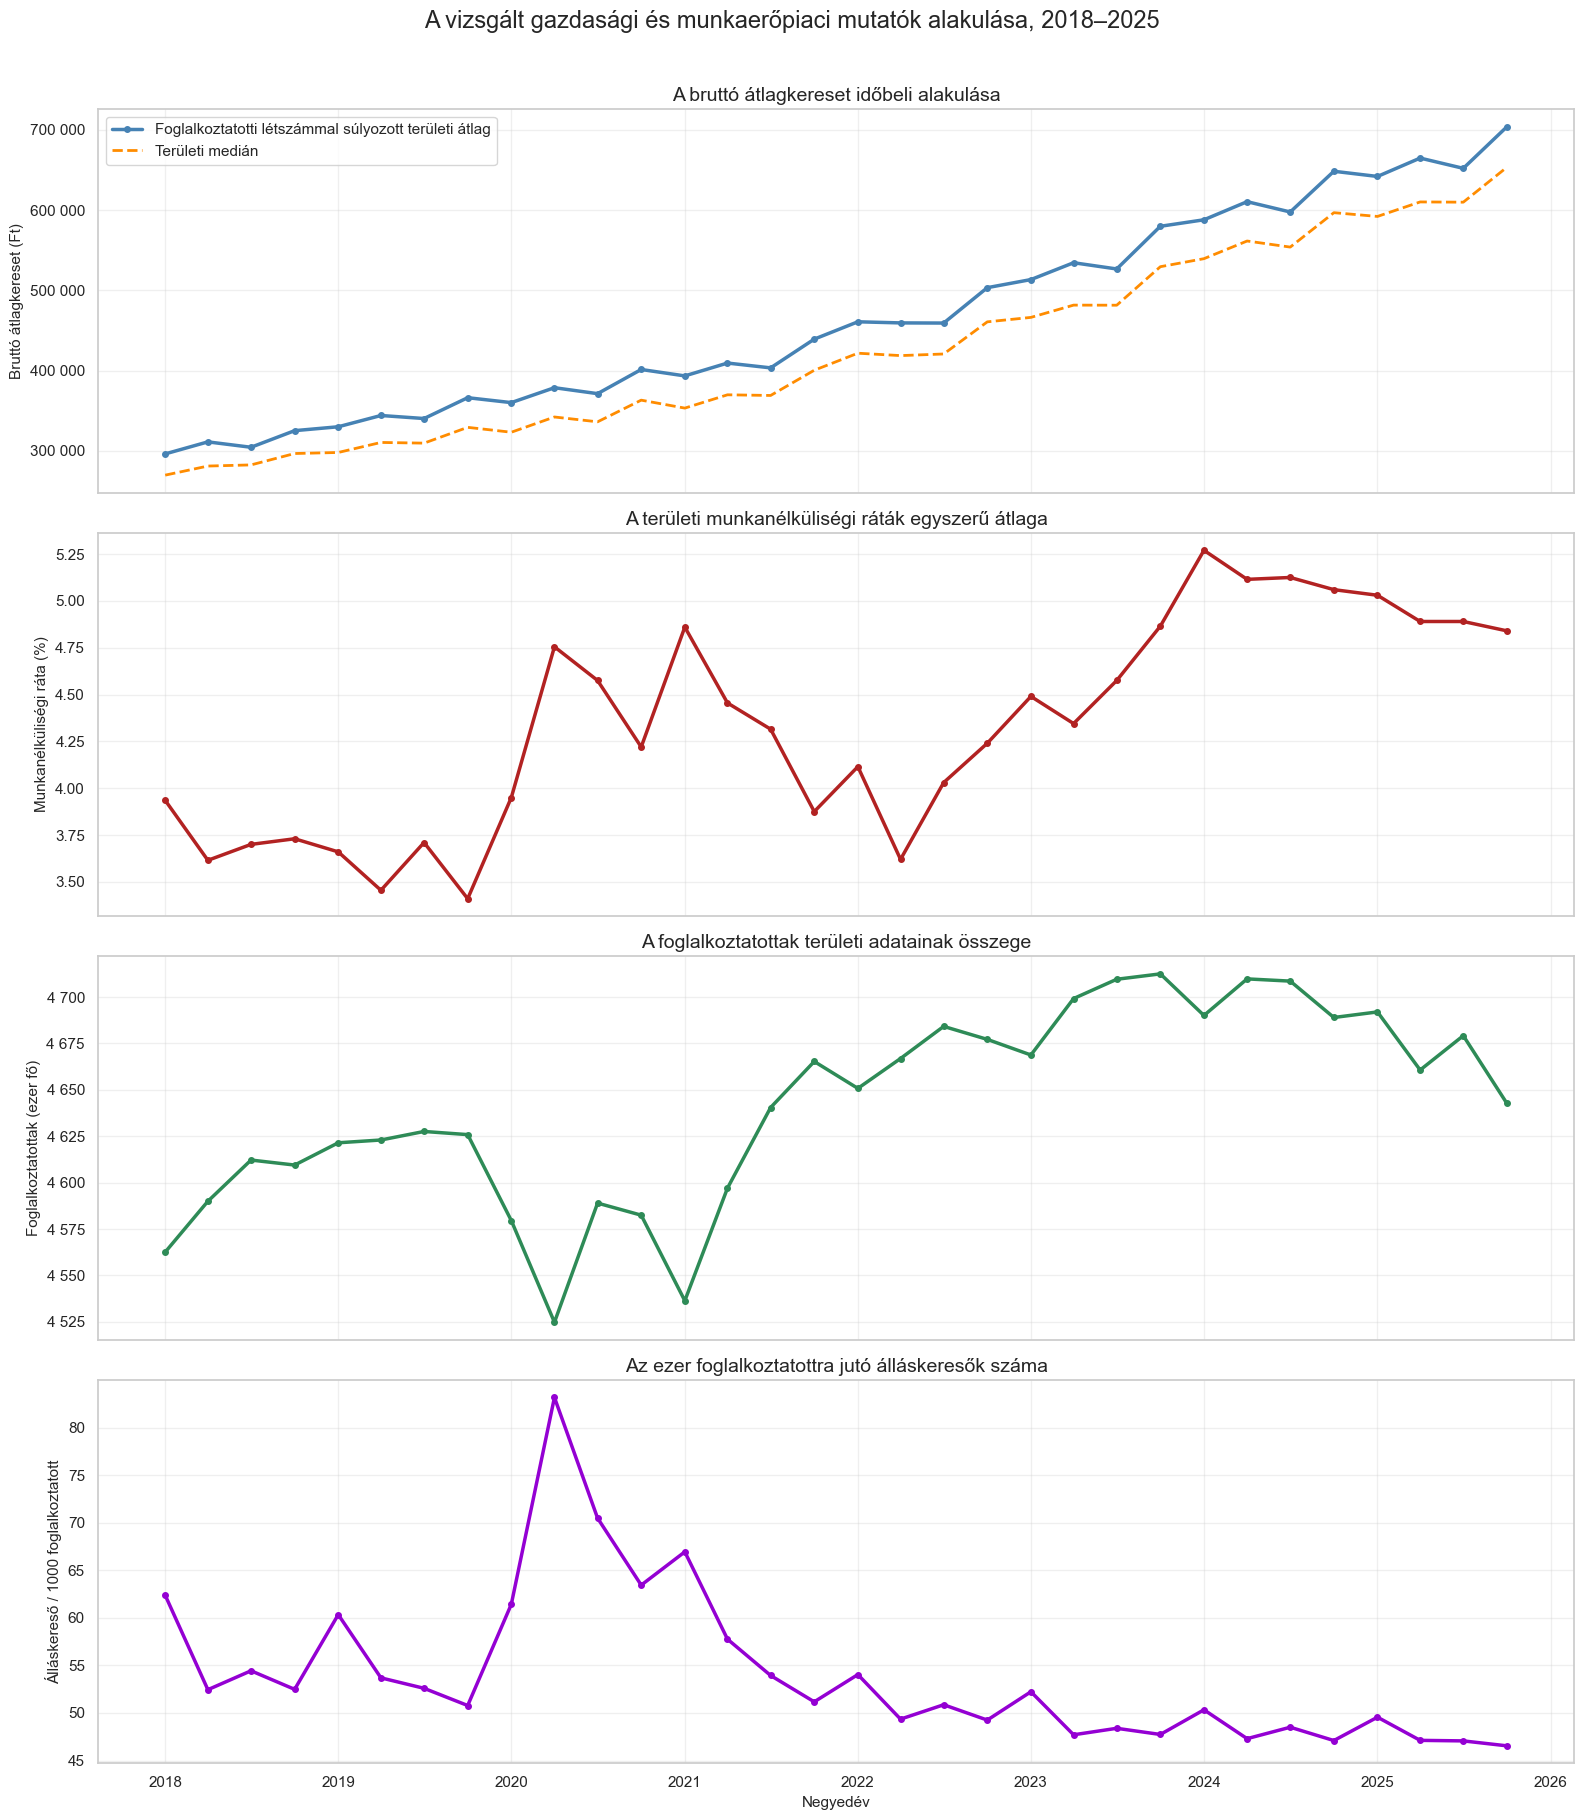

In [6]:

import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

def thousands_formatter(value, position):

    return (
        f"{value:,.0f}"
        .replace(",", " ")
    )

fig, axes = plt.subplots(
    4,
    1,
    figsize=(16, 18),
    sharex=True
)
# 1. BÉRTREND

axes[0].plot(
    quarterly_economic_trends.index,
    quarterly_economic_trends[
        "Foglalkoztatással_súlyozott_átlagbér"
    ],
    marker="o",
    markersize=4,
    linewidth=2.5,
    color="steelblue",
    label=(
        "Foglalkoztatotti létszámmal "
        "súlyozott területi átlag"
    )
)

axes[0].plot(
    quarterly_economic_trends.index,
    quarterly_economic_trends[
        "Területi_medián_bér"
    ],
    linewidth=2,
    linestyle="--",
    color="darkorange",
    label="Területi medián"
)

axes[0].set_ylabel(
    "Bruttó átlagkereset (Ft)"
)

axes[0].set_title(
    "A bruttó átlagkereset időbeli alakulása"
)

axes[0].yaxis.set_major_formatter(
    FuncFormatter(
        thousands_formatter
    )
)

axes[0].legend()

axes[0].grid(
    alpha=0.3
)

# 2. MUNKANÉLKÜLISÉGI RÁTA

axes[1].plot(
    quarterly_economic_trends.index,
    quarterly_economic_trends[
        "Munkanélküliségi_ráta_területi_átlag"
    ],
    marker="o",
    markersize=4,
    linewidth=2.5,
    color="firebrick"
)

axes[1].set_ylabel(
    "Munkanélküliségi ráta (%)"
)

axes[1].set_title(
    "A területi munkanélküliségi ráták egyszerű átlaga"
)

axes[1].grid(
    alpha=0.3
)

# 3. FOGLALKOZTATOTTAK SZÁMA

axes[2].plot(
    quarterly_economic_trends.index,
    quarterly_economic_trends[
        "Foglalkoztatottak_összesen_ezer_fő"
    ],
    marker="o",
    markersize=4,
    linewidth=2.5,
    color="seagreen"
)

axes[2].set_ylabel(
    "Foglalkoztatottak (ezer fő)"
)

axes[2].set_title(
    "A foglalkoztatottak területi adatainak összege"
)

axes[2].yaxis.set_major_formatter(
    FuncFormatter(
        thousands_formatter
    )
)

axes[2].grid(
    alpha=0.3
)

# 4. ÁLLÁSKERESŐI ARÁNY

axes[3].plot(
    quarterly_economic_trends.index,
    quarterly_economic_trends[
        "Álláskeresők_1000_foglalkoztatottra"
    ],
    marker="o",
    markersize=4,
    linewidth=2.5,
    color="darkviolet"
)

axes[3].set_ylabel(
    "Álláskereső / 1000 foglalkoztatott"
)

axes[3].set_title(
    "Az ezer foglalkoztatottra jutó álláskeresők száma"
)

axes[3].set_xlabel(
    "Negyedév"
)

axes[3].grid(
    alpha=0.3
)

# KÖZÖS IDŐTENGELY

for ax in axes:

    ax.xaxis.set_major_locator(
        mdates.YearLocator()
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y")
    )


fig.suptitle(
    "A vizsgált gazdasági és munkaerőpiaci mutatók "
    "alakulása, 2018–2025",
    fontsize=17,
    y=1.01
)


plt.tight_layout()


fig.savefig(
    FIGURES
    / "gazdasagi_munkaeropiaci_trendek_2018_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
quarterly_economic_trends.to_csv(
    PROCESSED
    / "KSH_negyedeves_gazdasagi_trendek.csv",
    encoding="utf-8-sig"
)


print(
    "A negyedéves trendadatok és az ábra elmentve."
)

A negyedéves trendadatok és az ábra elmentve.


## A bérnövekedés és a negyedéves szezonalitás vizsgálata

A nominális bérszint hosszú távú emelkedése mellett az egyes
negyedévek között rendszeres eltérések figyelhetők meg. Ezért
külön vizsgáljuk az előző év azonos negyedévéhez viszonyított
bérnövekedést és az egymást követő negyedévek közötti
változásokat.

Az éves változás kevésbé érzékeny a szezonalitásra, míg a
negyedéves változás alkalmas annak bemutatására, hogy bizonyos
negyedévekben rendszeresen magasabb vagy alacsonyabb
bérdinamika figyelhető-e meg.

In [8]:
# ÉVES BÉRNÖVEKEDÉS IDŐBELI ÖSSZESÍTÉSE

yoy_wage_growth = (
    df_eda
    .dropna(
        subset=[
            "Bér_Növekedés_YoY_%"
        ]
    )
    .groupby("Dátum")
    .agg(
        Átlagos_YoY_növekedés=(
            "Bér_Növekedés_YoY_%",
            "mean"
        ),

        Medián_YoY_növekedés=(
            "Bér_Növekedés_YoY_%",
            "median"
        ),

        Alsó_kvartilis=(
            "Bér_Növekedés_YoY_%",
            lambda values:
                values.quantile(0.25)
        ),

        Felső_kvartilis=(
            "Bér_Növekedés_YoY_%",
            lambda values:
                values.quantile(0.75)
        ),

        Minimum=(
            "Bér_Növekedés_YoY_%",
            "min"
        ),

        Maximum=(
            "Bér_Növekedés_YoY_%",
            "max"
        ),

        Területi_egységek=(
            "Területi egység neve",
            "nunique"
        )
    )
    .sort_index()
)


assert len(
    yoy_wage_growth
) == 28

assert (
    yoy_wage_growth[
        "Területi_egységek"
    ]
    == 20
).all()


print(
    "YoY bérnövekedéssel rendelkező negyedévek:",
    len(yoy_wage_growth)
)

display(
    yoy_wage_growth
    .round(2)
    .tail(8)
)

YoY bérnövekedéssel rendelkező negyedévek: 28


,Átlagos_YoY_növekedés,Medián_YoY_növekedés,Alsó_kvartilis,Felső_kvartilis,Minimum,Maximum,Területi_egységek
Dátum,,,,,,,
2024-01-01,14.53,14.37,14.15,15.27,11.90,17.05,20
2024-04-01,14.39,14.17,12.92,15.40,11.30,18.12,20
2024-07-01,13.77,13.73,12.77,14.43,10.44,16.78,20
2024-10-01,11.90,11.70,11.04,12.54,10.15,14.00,20
2025-01-01,9.17,9.18,8.78,9.58,6.59,11.17,20
2025-04-01,8.99,8.91,8.36,9.53,7.33,11.69,20
2025-07-01,9.15,9.05,8.54,9.57,8.23,10.45,20
2025-10-01,9.04,9.22,8.19,9.64,7.55,11.32,20


In [9]:
# QOQ BÉRNÖVEKEDÉS NEGYEDÉVENKÉNTI ELOSZLÁSA

quarter_labels = {
    1: "Q1",
    2: "Q2",
    3: "Q3",
    4: "Q4"
}


seasonal_wage_data = (
    df_eda
    .dropna(
        subset=[
            "Bér_Növekedés_QoQ_%"
        ]
    )
    .copy()
)


seasonal_wage_data[
    "Negyedév_felirat"
] = (
    seasonal_wage_data[
        "Negyedév"
    ]
    .map(
        quarter_labels
    )
)


seasonal_wage_data[
    "Negyedév_felirat"
] = pd.Categorical(
    seasonal_wage_data[
        "Negyedév_felirat"
    ],
    categories=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ],
    ordered=True
)


seasonality_summary = (
    seasonal_wage_data
    .groupby(
        "Negyedév_felirat",
        observed=True
    )
    .agg(
        Átlagos_QoQ_növekedés=(
            "Bér_Növekedés_QoQ_%",
            "mean"
        ),

        Medián_QoQ_növekedés=(
            "Bér_Növekedés_QoQ_%",
            "median"
        ),

        QoQ_szórás=(
            "Bér_Növekedés_QoQ_%",
            "std"
        ),

        Minimum=(
            "Bér_Növekedés_QoQ_%",
            "min"
        ),

        Maximum=(
            "Bér_Növekedés_QoQ_%",
            "max"
        ),

        Pozitív_változások_aránya=(
            "Bér_Növekedés_QoQ_%",
            lambda values:
                (
                    values > 0
                ).mean()
                *
                100
        ),

        Megfigyelések=(
            "Bér_Növekedés_QoQ_%",
            "size"
        )
    )
)


assert len(
    seasonality_summary
) == 4


print("=" * 80)
print("NEGYEDÉVES BÉRNÖVEKEDÉS SZEZONÁLIS ÖSSZESÍTÉSE")
print("=" * 80)

display(
    seasonality_summary.round(2)
)

NEGYEDÉVES BÉRNÖVEKEDÉS SZEZONÁLIS ÖSSZESÍTÉSE


,Átlagos_QoQ_növekedés,Medián_QoQ_növekedés,QoQ_szórás,Minimum,Maximum,Pozitív_változások_aránya,Megfigyelések
Negyedév_felirat,,,,,,,
Q1,0.69,0.28,3.21,-6.49,14.08,51.43,140
Q2,3.99,3.63,2.80,-4.03,14.39,93.12,160
Q3,-0.94,-0.70,1.91,-7.91,2.59,31.25,160
Q4,7.75,7.67,2.19,2.68,12.93,100.00,160


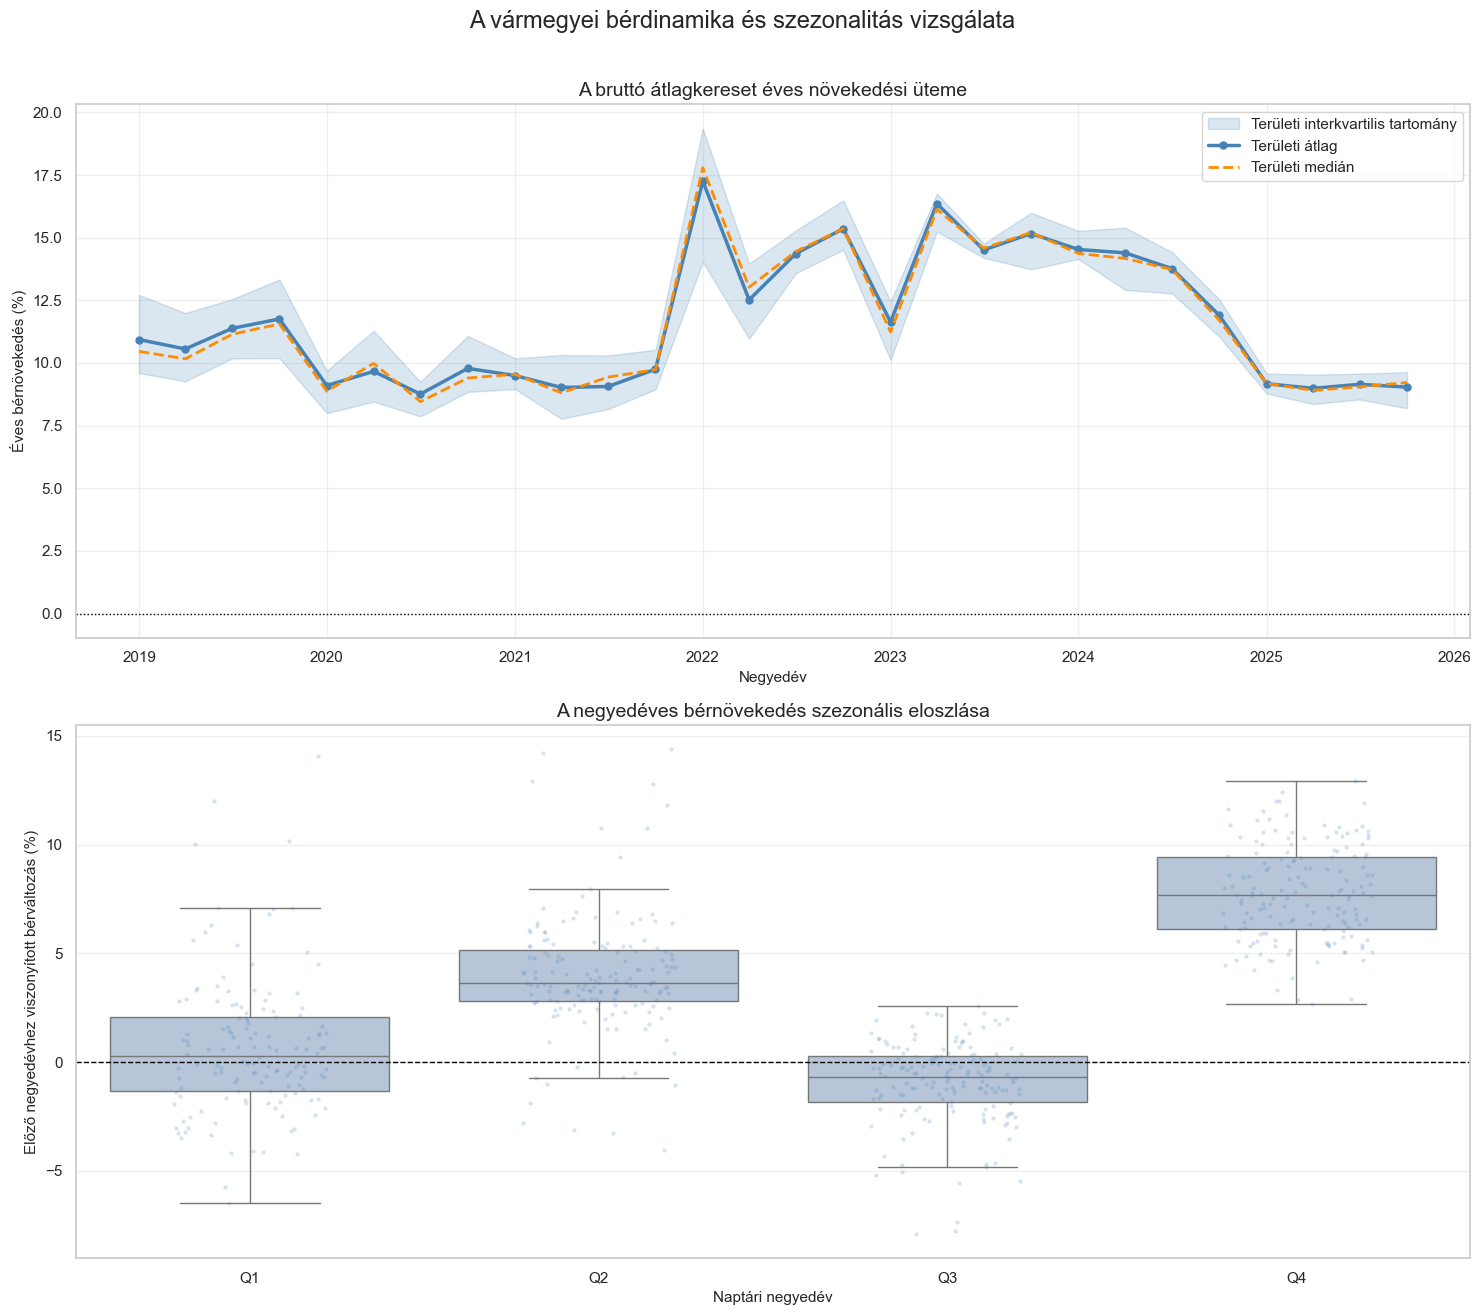

In [10]:
# BÉRNÖVEKEDÉSI ÉS SZEZONALITÁSI ÁBRÁK

fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 13)
)

# 1. ÉVES BÉRNÖVEKEDÉS IDŐBEN

axes[0].fill_between(
    yoy_wage_growth.index,
    yoy_wage_growth[
        "Alsó_kvartilis"
    ],
    yoy_wage_growth[
        "Felső_kvartilis"
    ],
    color="steelblue",
    alpha=0.20,
    label="Területi interkvartilis tartomány"
)


axes[0].plot(
    yoy_wage_growth.index,
    yoy_wage_growth[
        "Átlagos_YoY_növekedés"
    ],
    marker="o",
    markersize=5,
    linewidth=2.5,
    color="steelblue",
    label="Területi átlag"
)


axes[0].plot(
    yoy_wage_growth.index,
    yoy_wage_growth[
        "Medián_YoY_növekedés"
    ],
    linewidth=2,
    linestyle="--",
    color="darkorange",
    label="Területi medián"
)


axes[0].axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)


axes[0].set_ylabel(
    "Éves bérnövekedés (%)"
)

axes[0].set_xlabel(
    "Negyedév"
)

axes[0].set_title(
    "A bruttó átlagkereset éves növekedési üteme"
)

axes[0].xaxis.set_major_locator(
    mdates.YearLocator()
)

axes[0].xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

axes[0].legend()

axes[0].grid(
    alpha=0.3
)

# 2. NEGYEDÉVES SZEZONALITÁS

sns.boxplot(
    data=seasonal_wage_data,
    x="Negyedév_felirat",
    y="Bér_Növekedés_QoQ_%",
    order=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ],
    showfliers=False,
    color="lightsteelblue",
    ax=axes[1]
)


sns.stripplot(
    data=seasonal_wage_data,
    x="Negyedév_felirat",
    y="Bér_Növekedés_QoQ_%",
    order=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ],
    color="steelblue",
    alpha=0.22,
    jitter=0.22,
    size=3,
    ax=axes[1]
)


axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)


axes[1].set_xlabel(
    "Naptári negyedév"
)

axes[1].set_ylabel(
    "Előző negyedévhez viszonyított bérváltozás (%)"
)

axes[1].set_title(
    "A negyedéves bérnövekedés szezonális eloszlása"
)

axes[1].grid(
    axis="y",
    alpha=0.3
)


fig.suptitle(
    "A vármegyei bérdinamika és szezonalitás vizsgálata",
    fontsize=17,
    y=1.01
)


plt.tight_layout()


fig.savefig(
    FIGURES
    / "bernovekedes_es_szezonalitas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
yoy_wage_growth.to_csv(
    PROCESSED
    / "KSH_YoY_bernovekedes_idoben.csv",
    encoding="utf-8-sig"
)


seasonality_summary.to_csv(
    PROCESSED
    / "KSH_QoQ_bernovekedes_szezonalitas.csv",
    encoding="utf-8-sig"
)


print(
    "A bérnövekedési és szezonális eredmények elmentve."
)

A bérnövekedési és szezonális eredmények elmentve.


## A területi gazdasági különbségek vizsgálata

A következő rész Budapest és a 19 vármegye gazdasági és
munkaerőpiaci különbségeit vizsgálja. A területi összehasonlítás
a 2025. évi átlagos bruttó keresetre, a 2018–2025 közötti
évesített nominális bérnövekedésre, valamint a teljes időszak
átlagos munkanélküliségi rátájára épül.

A 2025. évi átlag használata csökkenti az egyetlen negyedév
szezonális hatásából eredő torzítást. Az évesített bérnövekedés
a 2018. és 2025. évi átlagos nominális kereset alapján készül.

In [12]:
# TERÜLETI GAZDASÁGI PROFILOK

regional_base_profile = (
    df_eda
    .groupby(
        "Területi egység neve"
    )
    .agg(
        Átlagbér_2018_2025=(
            "Bruttó_átlagkereset_HUF",
            "mean"
        ),

        Átlagos_YoY_bérnövekedés=(
            "Bér_Növekedés_YoY_%",
            "mean"
        ),

        Átlagos_munkanélküliségi_ráta=(
            "Munkanélküliségi_ráta_%",
            "mean"
        ),

        Munkanélküliségi_ráta_szórása=(
            "Munkanélküliségi_ráta_%",
            "std"
        ),

        Álláskeresők_összesen=(
            "Álláskeresők_száma",
            "sum"
        ),

        Foglalkoztatottak_összesen_ezer_fő=(
            "Foglalkoztatottak, ezer fő",
            "sum"
        ),

        Átlagos_foglalkoztatottak_ezer_fő=(
            "Foglalkoztatottak, ezer fő",
            "mean"
        ),

        Megfigyelések=(
            "Dátum",
            "size"
        )
    )
)


regional_base_profile[
    "Álláskeresők_1000_foglalkoztatottra"
] = (
    regional_base_profile[
        "Álláskeresők_összesen"
    ]
    /
    regional_base_profile[
        "Foglalkoztatottak_összesen_ezer_fő"
    ]
)

# ÉVES ÁTLAGBÉREK TERÜLETENKÉNT

regional_annual_wages = (
    df_eda
    .groupby(
        [
            "Területi egység neve",
            "Év"
        ]
    )[
        "Bruttó_átlagkereset_HUF"
    ]
    .mean()
    .unstack("Év")
)

assert 2018 in regional_annual_wages.columns
assert 2025 in regional_annual_wages.columns

regional_wage_endpoints = (
    regional_annual_wages[
        [
            2018,
            2025
        ]
    ]
    .rename(
        columns={
            2018: "Átlagbér_2018",
            2025: "Átlagbér_2025"
        }
    )
)

regional_profile = (
    regional_base_profile
    .join(
        regional_wage_endpoints
    )
)

year_difference = (
    2025
    -
    2018
)

regional_profile[
    "Évesített_bérnövekedés_2018_2025_%"
] = (
    (
        regional_profile[
            "Átlagbér_2025"
        ]
        /
        regional_profile[
            "Átlagbér_2018"
        ]
    )
    **
    (
        1
        /
        year_difference
    )
    -
    1
) * 100


# RANGSOROK

regional_profile[
    "Bérszint_rangsor"
] = (
    regional_profile[
        "Átlagbér_2025"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

regional_profile[
    "Bérnövekedési_rangsor"
] = (
    regional_profile[
        "Évesített_bérnövekedés_2018_2025_%"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

regional_profile[
    "Munkanélküliségi_rangsor"
] = (
    regional_profile[
        "Átlagos_munkanélküliségi_ráta"
    ]
    .rank(
        ascending=True,
        method="min"
    )
    .astype(int)
)

# ELLENŐRZÉSEK

assert len(
    regional_profile
) == 20

assert (
    regional_profile[
        "Megfigyelések"
    ]
    == 32
).all()

assert (
    regional_profile[
        [
            "Átlagbér_2018",
            "Átlagbér_2025",
            "Évesített_bérnövekedés_2018_2025_%",
            "Átlagos_munkanélküliségi_ráta",
            "Álláskeresők_1000_foglalkoztatottra"
        ]
    ]
    .notna()
    .all()
    .all()
)

print("TERÜLETI GAZDASÁGI PROFILOK")


display(
    regional_profile[
        [
            "Átlagbér_2018",
            "Átlagbér_2025",
            "Évesített_bérnövekedés_2018_2025_%",
            "Átlagos_YoY_bérnövekedés",
            "Átlagos_munkanélküliségi_ráta",
            "Álláskeresők_1000_foglalkoztatottra",
            "Bérszint_rangsor",
            "Bérnövekedési_rangsor",
            "Munkanélküliségi_rangsor"
        ]
    ]
    .sort_values(
        "Átlagbér_2025",
        ascending=False
    )
    .round(2)
)

TERÜLETI GAZDASÁGI PROFILOK


,Átlagbér_2018,Átlagbér_2025,Évesített_bérnövekedés_2018_2025_%,Átlagos_YoY_bérnövekedés,Átlagos_munkanélküliségi_ráta,Álláskeresők_1000_foglalkoztatottra,Bérszint_rangsor,Bérnövekedési_rangsor,Munkanélküliségi_rangsor
Területi egység neve,,,,,,,,,
Budapest,413944.0,851211.0,10.85,10.89,2.70,21.69,1,20,6
Győr-Moson-Sopron,341060.0,737115.0,11.64,11.73,1.72,15.41,2,9,1
Komárom-Esztergom,323812.0,696992.0,11.57,11.61,2.12,33.05,3,13,2
Fejér,321633.0,680039.0,11.29,11.33,2.55,39.41,4,16,5
Tolna,304441.0,663112.0,11.76,11.78,4.10,65.33,5,7,12
Heves,305135.0,647641.0,11.35,11.38,3.05,83.99,6,15,9
Pest,298755.0,646120.0,11.65,11.68,2.74,29.94,7,8,7
Vas,303047.0,636925.0,11.19,11.22,2.40,34.89,8,19,4
Veszprém,297585.0,627027.0,11.23,11.27,2.20,40.37,9,18,3


In [13]:
# TERÜLETI RANGSORÁBRA-FÜGGVÉNY

def plot_regional_ranking(
    data,
    column,
    xlabel,
    title,
    color,
    filename,
    value_formatter,
    axis_formatter=None
):

    plot_data = (
        data
        .sort_values(
            column,
            ascending=True
        )
    )

    fig, ax = plt.subplots(
        figsize=(13, 9)
    )

    bars = ax.barh(
        plot_data.index,
        plot_data[column],
        color=color,
        alpha=0.85
    )

    maximum_value = (
        plot_data[column].max()
    )

    for bar, value in zip(
        bars,
        plot_data[column]
    ):

        ax.text(
            value
            +
            maximum_value * 0.01,
            bar.get_y()
            +
            bar.get_height() / 2,
            value_formatter(value),
            va="center",
            fontsize=9
        )

    ax.set_xlim(
        0,
        maximum_value * 1.19
    )

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        "Területi egység"
    )

    ax.set_title(
        title
    )

    ax.grid(
        axis="x",
        alpha=0.3
    )

    if axis_formatter is not None:

        ax.xaxis.set_major_formatter(
            FuncFormatter(
                axis_formatter
            )
        )

    plt.tight_layout()

    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

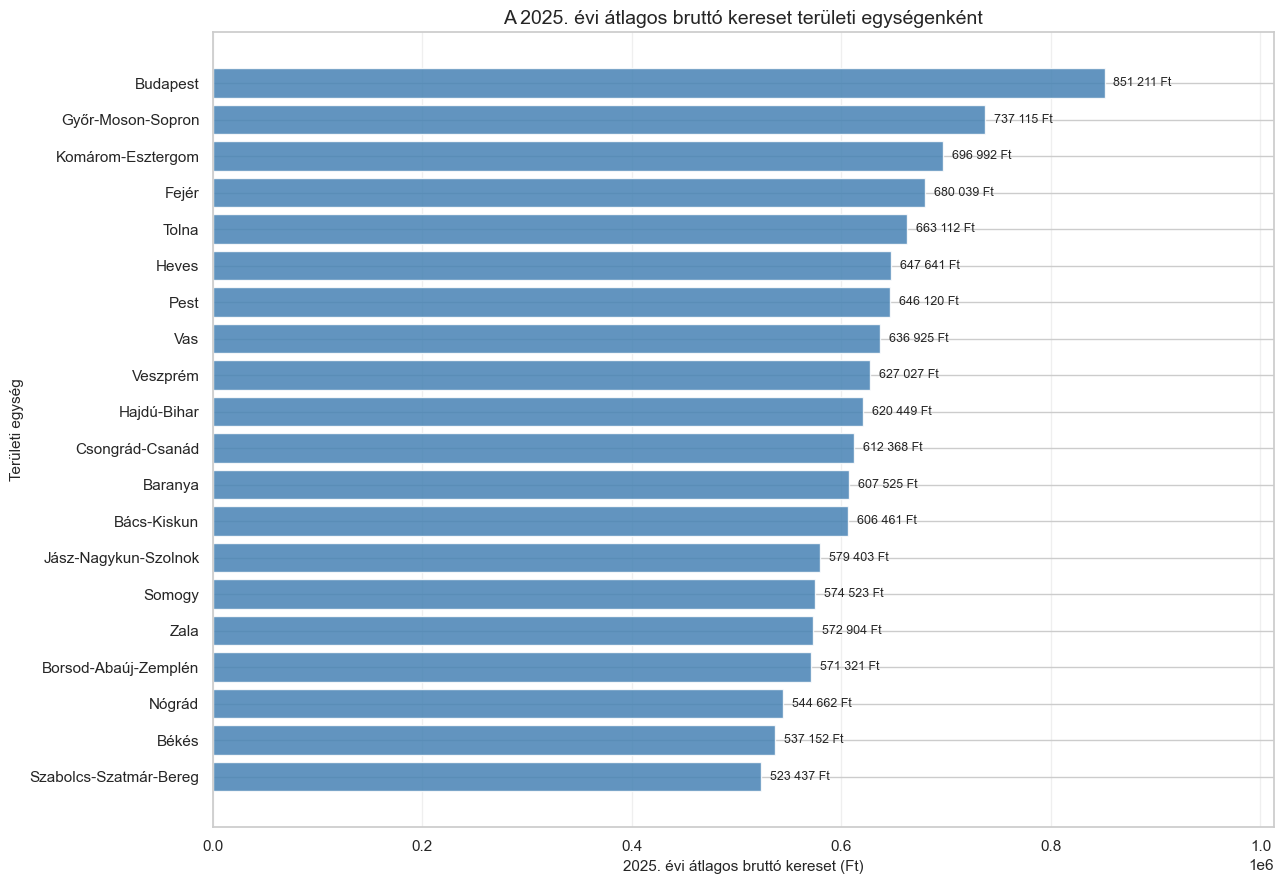

In [14]:
plot_regional_ranking(
    data=regional_profile,
    column="Átlagbér_2025",
    xlabel="2025. évi átlagos bruttó kereset (Ft)",
    title=(
        "A 2025. évi átlagos bruttó kereset "
        "területi egységenként"
    ),
    color="steelblue",
    filename="regionalis_atlagber_2025.png",
    value_formatter=lambda value:
        (
            f"{value:,.0f} Ft"
            .replace(",", " ")
        )
)
axis_formatter=thousands_formatter

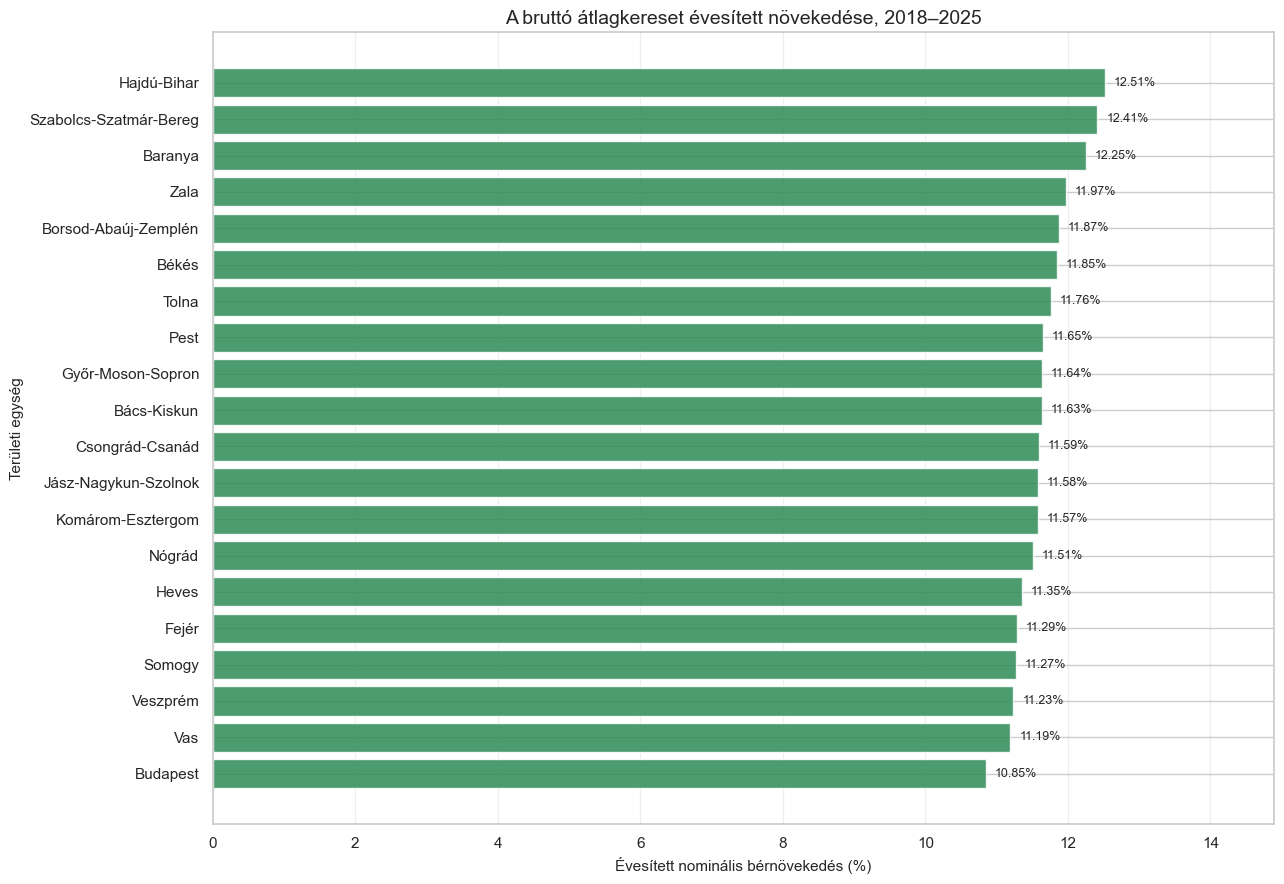

In [15]:
plot_regional_ranking(
    data=regional_profile,
    column="Évesített_bérnövekedés_2018_2025_%",
    xlabel="Évesített nominális bérnövekedés (%)",
    title=(
        "A bruttó átlagkereset évesített növekedése, "
        "2018–2025"
    ),
    color="seagreen",
    filename="regionalis_evesitett_bernovekedes.png",
    value_formatter=lambda value:
        f"{value:.2f}%"
)

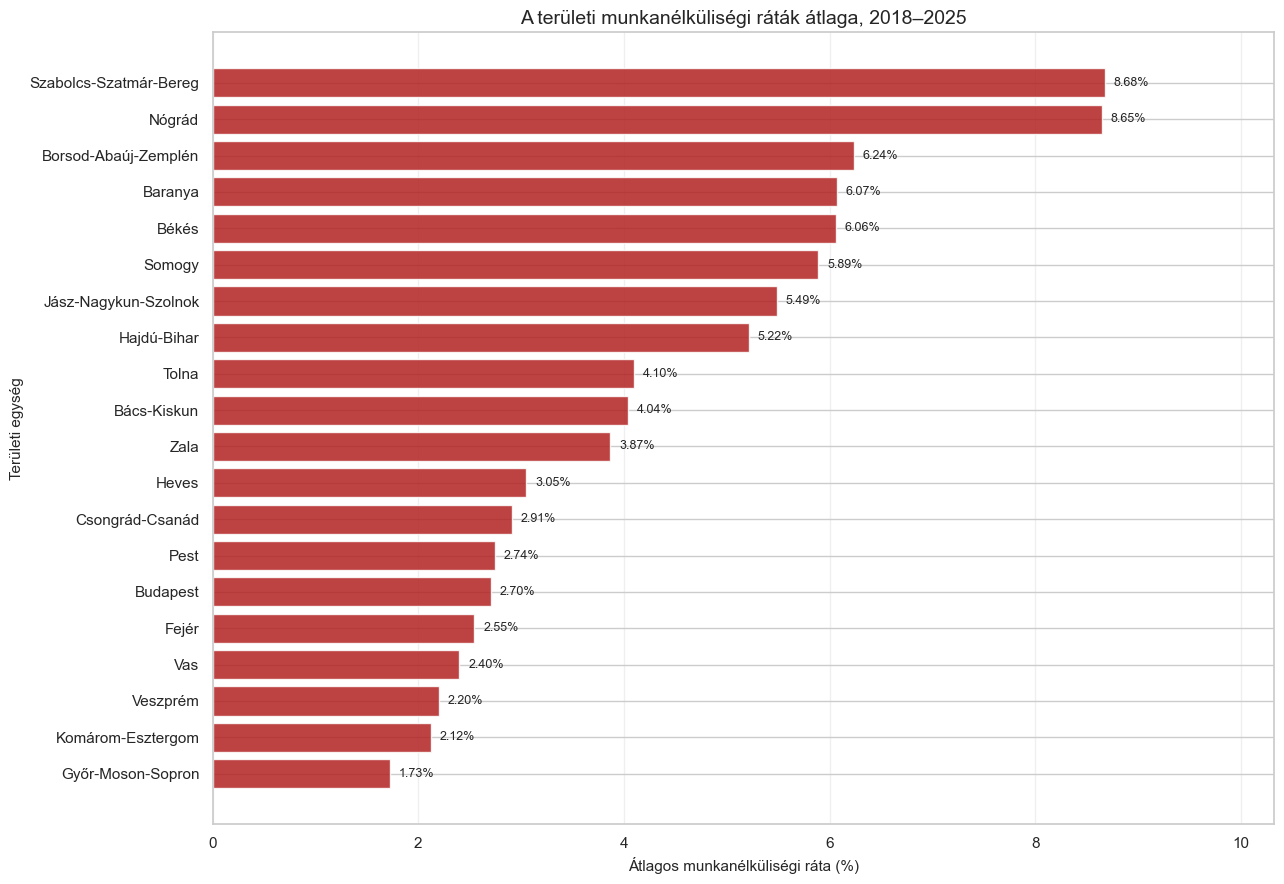

In [16]:
plot_regional_ranking(
    data=regional_profile,
    column="Átlagos_munkanélküliségi_ráta",
    xlabel="Átlagos munkanélküliségi ráta (%)",
    title=(
        "A területi munkanélküliségi ráták átlaga, "
        "2018–2025"
    ),
    color="firebrick",
    filename="regionalis_atlagos_munkanelkuliseg.png",
    value_formatter=lambda value:
        f"{value:.2f}%"
)

In [17]:
regional_profile.to_csv(
    PROCESSED
    / "KSH_teruleti_gazdasagi_profilok.csv",
    encoding="utf-8-sig"
)


regional_annual_wages.to_csv(
    PROCESSED
    / "KSH_teruleti_eves_atlagberek.csv",
    encoding="utf-8-sig"
)


print(
    "A területi gazdasági profilok és rangsorábrák elmentve."
)

A területi gazdasági profilok és rangsorábrák elmentve.


## A területi gazdasági mutatók közötti kapcsolatok

A korrelációs elemzés a 20 területi egység összesített gazdasági
profiljaira épül. Ezzel elkerülhető, hogy a valamennyi területen
jelen lévő nominális időbeli bértrend mesterségesen felerősítse
a változók közötti kapcsolatokat.

A Pearson-féle korreláció a lineáris kapcsolatot, míg a
Spearman-féle rangkorreláció a monoton kapcsolatot méri.
A korrelációk leíró jellegűek, nem bizonyítanak ok-okozati
összefüggést. Az elemszám 20 területi egység.

In [18]:
# TERÜLETI KORRELÁCIÓS ADATBÁZIS

correlation_variables = {
    "Átlagbér_2025":
        "2025. évi átlagbér",

    "Évesített_bérnövekedés_2018_2025_%":
        "Évesített bérnövekedés",

    "Átlagos_munkanélküliségi_ráta":
        "Munkanélküliségi ráta",

    "Álláskeresők_1000_foglalkoztatottra":
        "Álláskeresői arány",

    "Átlagos_foglalkoztatottak_ezer_fő":
        "Foglalkoztatotti létszám"
}

regional_correlation_data = (
    regional_profile[
        list(
            correlation_variables.keys()
        )
    ]
    .rename(
        columns=correlation_variables
    )
    .copy()
)

assert regional_correlation_data.shape == (
    20,
    5
)

assert (
    regional_correlation_data
    .notna()
    .all()
    .all()
)

pearson_correlation_matrix = (
    regional_correlation_data
    .corr(
        method="pearson"
    )
)

spearman_correlation_matrix = (
    regional_correlation_data
    .corr(
        method="spearman"
    )
)

print(
    "Korrelációs adatbázis mérete:",
    regional_correlation_data.shape
)

display(
    pearson_correlation_matrix.round(3)
)

display(
    spearman_correlation_matrix.round(3)
)

Korrelációs adatbázis mérete: (20, 5)


,2025. évi átlagbér,Évesített bérnövekedés,Munkanélküliségi ráta,Álláskeresői arány,Foglalkoztatotti létszám
2025. évi átlagbér,1.000,-0.531,-0.716,-0.711,0.616
Évesített bérnövekedés,-0.531,1.000,0.530,0.423,-0.271
Munkanélküliségi ráta,-0.716,0.530,1.000,0.893,-0.250
Álláskeresői arány,-0.711,0.423,0.893,1.000,-0.377
Foglalkoztatotti létszám,0.616,-0.271,-0.250,-0.377,1.000


,2025. évi átlagbér,Évesített bérnövekedés,Munkanélküliségi ráta,Álláskeresői arány,Foglalkoztatotti létszám
2025. évi átlagbér,1.000,-0.442,-0.826,-0.731,0.214
Évesített bérnövekedés,-0.442,1.000,0.523,0.316,0.197
Munkanélküliségi ráta,-0.826,0.523,1.000,0.857,-0.131
Álláskeresői arány,-0.731,0.316,0.857,1.000,-0.290
Foglalkoztatotti létszám,0.214,0.197,-0.131,-0.290,1.000


In [19]:
# MAGAS KORRELÁCIÓJÚ VÁLTOZÓPÁROK

high_correlation_rows = []

correlation_columns = (
    pearson_correlation_matrix.columns
)

for first_index in range(
    len(correlation_columns)
):

    for second_index in range(
        first_index + 1,
        len(correlation_columns)
    ):

        first_variable = (
            correlation_columns[
                first_index
            ]
        )

        second_variable = (
            correlation_columns[
                second_index
            ]
        )


        pearson_value = (
            pearson_correlation_matrix.loc[
                first_variable,
                second_variable
            ]
        )

        spearman_value = (
            spearman_correlation_matrix.loc[
                first_variable,
                second_variable
            ]
        )


        high_correlation_rows.append(
            {
                "Első változó":
                    first_variable,

                "Második változó":
                    second_variable,

                "Pearson_korreláció":
                    pearson_value,

                "Spearman_korreláció":
                    spearman_value,

                "Abszolút_Pearson":
                    abs(
                        pearson_value
                    )
            }
        )

correlation_pair_summary = (
    pd.DataFrame(
        high_correlation_rows
    )
    .sort_values(
        "Abszolút_Pearson",
        ascending=False
    )
)

print(
    "A legerősebb területi kapcsolatok:"
)

display(
    correlation_pair_summary
    .drop(
        columns="Abszolút_Pearson"
    )
    .head(10)
    .round(3)
)

A legerősebb területi kapcsolatok:


,Első változó,Második változó,Pearson_korreláció,Spearman_korreláció
7,Munkanélküliségi ráta,Álláskeresői arány,0.893,0.857
1,2025. évi átlagbér,Munkanélküliségi ráta,-0.716,-0.826
2,2025. évi átlagbér,Álláskeresői arány,-0.711,-0.731
3,2025. évi átlagbér,Foglalkoztatotti létszám,0.616,0.214
0,2025. évi átlagbér,Évesített bérnövekedés,-0.531,-0.442
4,Évesített bérnövekedés,Munkanélküliségi ráta,0.530,0.523
5,Évesített bérnövekedés,Álláskeresői arány,0.423,0.316
9,Álláskeresői arány,Foglalkoztatotti létszám,-0.377,-0.290
6,Évesített bérnövekedés,Foglalkoztatotti létszám,-0.271,0.197
8,Munkanélküliségi ráta,Foglalkoztatotti létszám,-0.250,-0.131


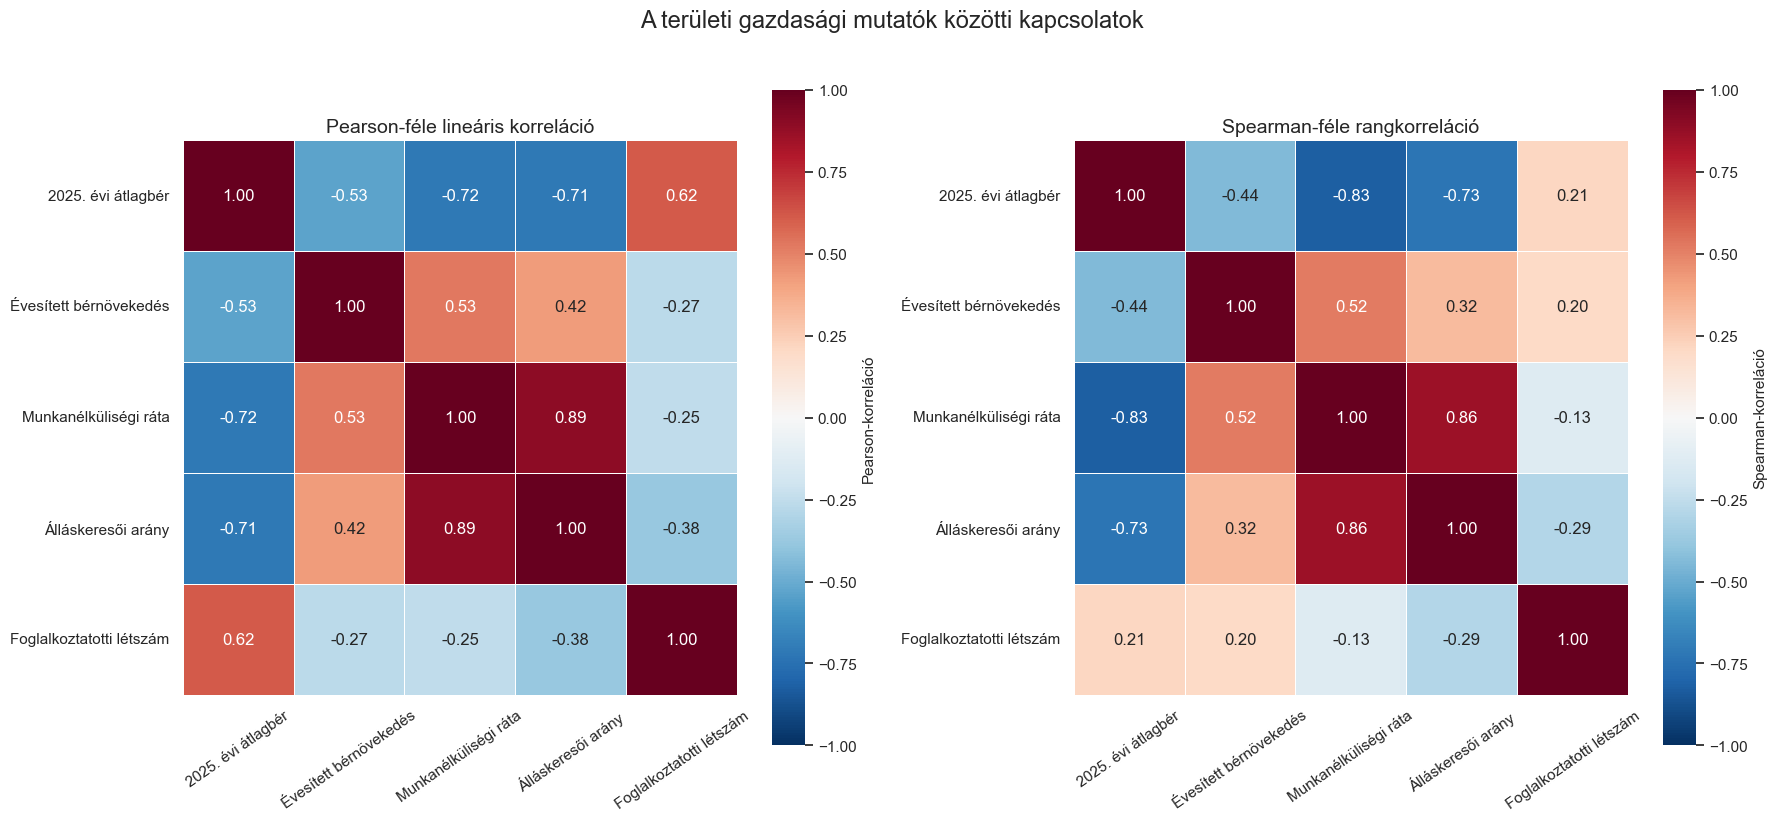

In [20]:
# TERÜLETI KORRELÁCIÓS HŐTÉRKÉPEK

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8)
)

sns.heatmap(
    pearson_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson-korreláció"
    },
    ax=axes[0]
)

axes[0].set_title(
    "Pearson-féle lineáris korreláció"
)

axes[0].tick_params(
    axis="x",
    rotation=35
)

axes[0].tick_params(
    axis="y",
    rotation=0
)


sns.heatmap(
    spearman_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Spearman-korreláció"
    },
    ax=axes[1]
)

axes[1].set_title(
    "Spearman-féle rangkorreláció"
)

axes[1].tick_params(
    axis="x",
    rotation=35
)

axes[1].tick_params(
    axis="y",
    rotation=0
)


fig.suptitle(
    "A területi gazdasági mutatók közötti kapcsolatok",
    fontsize=17,
    y=1.02
)


plt.tight_layout()


fig.savefig(
    FIGURES
    / "teruleti_korrelacios_heatmapek.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# SCATTERÁBRÁKHOZ HASZNÁLT ADATBÁZIS

regional_scatter_data = (
    regional_profile
    .reset_index()
    .copy()
)

def annotate_extreme_regions(
    ax,
    data,
    x_column,
    y_column
):

    selected_indices = set()


    for column in [
        x_column,
        y_column
    ]:

        selected_indices.update(
            data
            .nlargest(
                3,
                column
            )
            .index
        )

        selected_indices.update(
            data
            .nsmallest(
                3,
                column
            )
            .index
        )


    for index in selected_indices:

        row = data.loc[index]

        ax.annotate(
            row[
                "Területi egység neve"
            ],
            (
                row[x_column],
                row[y_column]
            ),
            xytext=(6, 5),
            textcoords="offset points",
            fontsize=8
        )

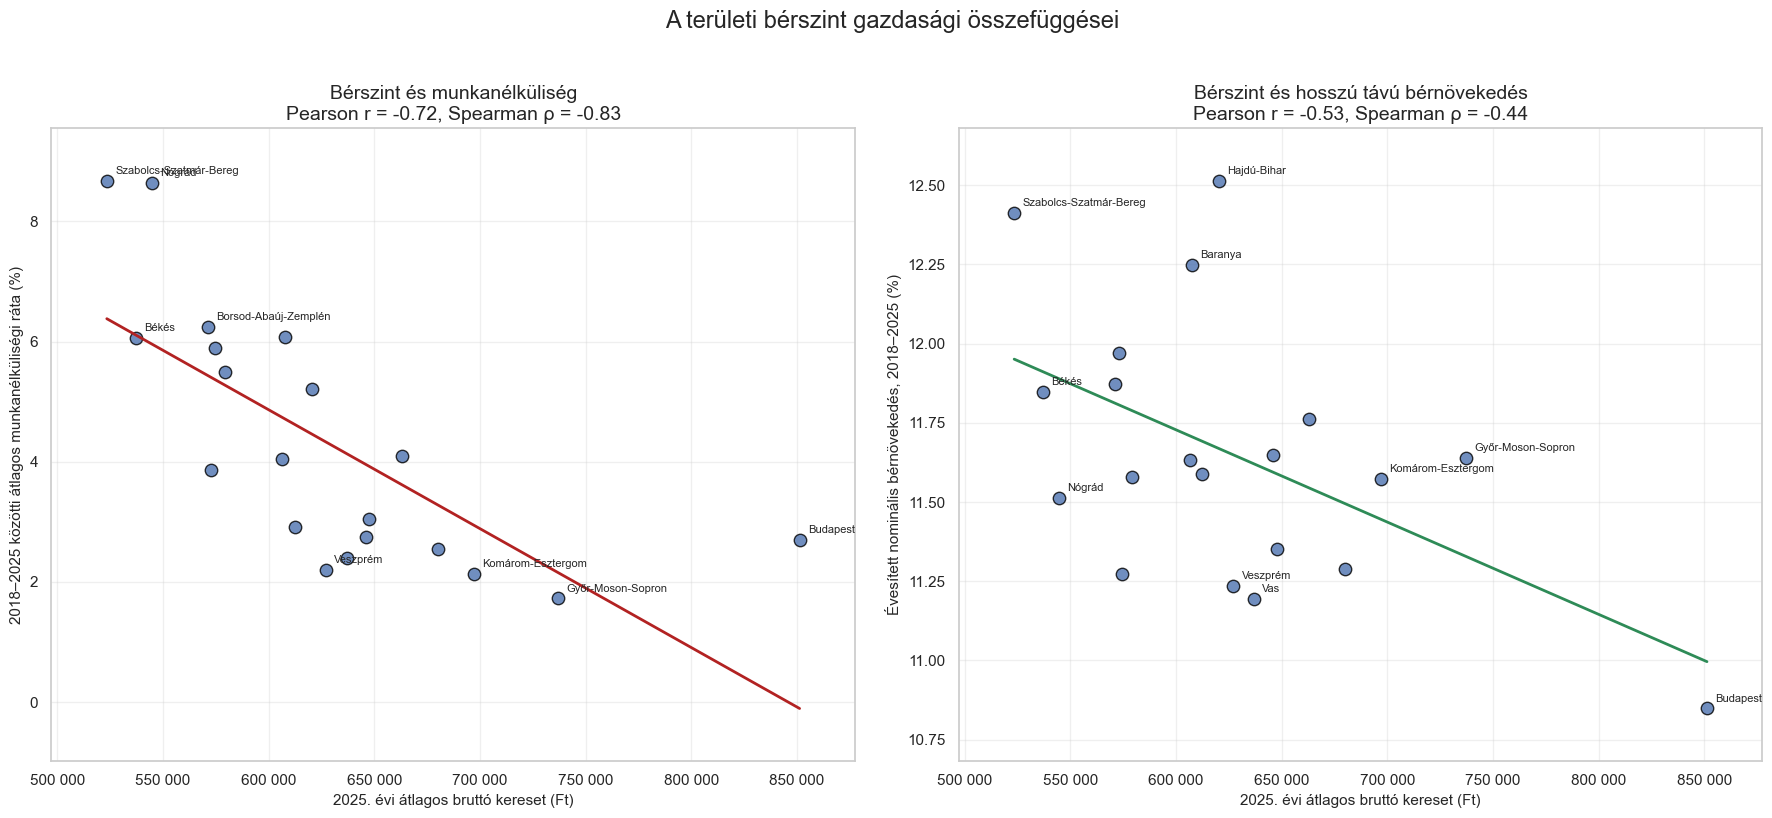

In [22]:
# BÉRSZINT, NÖVEKEDÉS ÉS MUNKANÉLKÜLISÉG

wage_unemployment_pearson = (
    regional_profile[
        "Átlagbér_2025"
    ]
    .corr(
        regional_profile[
            "Átlagos_munkanélküliségi_ráta"
        ],
        method="pearson"
    )
)

wage_unemployment_spearman = (
    regional_profile[
        "Átlagbér_2025"
    ]
    .corr(
        regional_profile[
            "Átlagos_munkanélküliségi_ráta"
        ],
        method="spearman"
    )
)


wage_growth_pearson = (
    regional_profile[
        "Átlagbér_2025"
    ]
    .corr(
        regional_profile[
            "Évesített_bérnövekedés_2018_2025_%"
        ],
        method="pearson"
    )
)

wage_growth_spearman = (
    regional_profile[
        "Átlagbér_2025"
    ]
    .corr(
        regional_profile[
            "Évesített_bérnövekedés_2018_2025_%"
        ],
        method="spearman"
    )
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8)
)


# BÉRSZINT ÉS MUNKANÉLKÜLISÉG

sns.regplot(
    data=regional_scatter_data,
    x="Átlagbér_2025",
    y="Átlagos_munkanélküliségi_ráta",
    ci=None,
    scatter_kws={
        "s": 80,
        "alpha": 0.8,
        "edgecolor": "black"
    },
    line_kws={
        "color": "firebrick",
        "linewidth": 2
    },
    ax=axes[0]
)


annotate_extreme_regions(
    axes[0],
    regional_scatter_data,
    "Átlagbér_2025",
    "Átlagos_munkanélküliségi_ráta"
)


axes[0].xaxis.set_major_formatter(
    FuncFormatter(
        thousands_formatter
    )
)

axes[0].set_xlabel(
    "2025. évi átlagos bruttó kereset (Ft)"
)

axes[0].set_ylabel(
    "2018–2025 közötti átlagos munkanélküliségi ráta (%)"
)

axes[0].set_title(
    "Bérszint és munkanélküliség\n"
    f"Pearson r = {wage_unemployment_pearson:.2f}, "
    f"Spearman ρ = {wage_unemployment_spearman:.2f}"
)

axes[0].grid(
    alpha=0.3
)

axes[0].margins(
    x=0.08,
    y=0.10
)


# BÉRSZINT ÉS HOSSZÚ TÁVÚ NÖVEKEDÉS

sns.regplot(
    data=regional_scatter_data,
    x="Átlagbér_2025",
    y="Évesített_bérnövekedés_2018_2025_%",
    ci=None,
    scatter_kws={
        "s": 80,
        "alpha": 0.8,
        "edgecolor": "black"
    },
    line_kws={
        "color": "seagreen",
        "linewidth": 2
    },
    ax=axes[1]
)


annotate_extreme_regions(
    axes[1],
    regional_scatter_data,
    "Átlagbér_2025",
    "Évesített_bérnövekedés_2018_2025_%"
)


axes[1].xaxis.set_major_formatter(
    FuncFormatter(
        thousands_formatter
    )
)

axes[1].set_xlabel(
    "2025. évi átlagos bruttó kereset (Ft)"
)

axes[1].set_ylabel(
    "Évesített nominális bérnövekedés, 2018–2025 (%)"
)

axes[1].set_title(
    "Bérszint és hosszú távú bérnövekedés\n"
    f"Pearson r = {wage_growth_pearson:.2f}, "
    f"Spearman ρ = {wage_growth_spearman:.2f}"
)

axes[1].grid(
    alpha=0.3
)

axes[1].margins(
    x=0.08,
    y=0.10
)


fig.suptitle(
    "A területi bérszint gazdasági összefüggései",
    fontsize=17,
    y=1.02
)


plt.tight_layout()


fig.savefig(
    FIGURES
    / "teruleti_berkapcsolatok_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
pearson_correlation_matrix.to_csv(
    PROCESSED
    / "KSH_teruleti_pearson_korrelacio.csv",
    encoding="utf-8-sig"
)


spearman_correlation_matrix.to_csv(
    PROCESSED
    / "KSH_teruleti_spearman_korrelacio.csv",
    encoding="utf-8-sig"
)


correlation_pair_summary.to_csv(
    PROCESSED
    / "KSH_teruleti_korrelacios_parok.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A területi korrelációs eredmények és ábrák elmentve."
)

A területi korrelációs eredmények és ábrák elmentve.


## A területi egységek bérdinamikájának együttmozgása

A vizsgálat Budapest és a vármegyék éves bérváltozásainak együttmozgását
elemzi. A korrelációt nem a nominális bérszintekből, hanem az éves
bérváltozási ütemekből számítjuk, mert a minden területen jelentkező
általános béremelkedés a bérszintek között mesterségesen magas
korrelációt eredményezhetne.

A Pearson-korreláció a lineáris együttmozgást, a Spearman-korreláció
pedig a változások rangsorának hasonlóságát mutatja. A korreláció
nem jelent oksági kapcsolatot, és önmagában nem bizonyítja, hogy
egyik terület változása előre jelzi egy másik terület későbbi változását.

In [24]:
# TERÜLET–TERÜLET KORRELÁCIÓ AZ ÉVES BÉRVÁLTOZÁS ALAPJÁN

REGION_COLUMN = "Területi egység neve"
DATE_COLUMN = "Dátum"
CORRELATION_COLUMN = "Bér_Növekedés_YoY_%"


# Negyedévek × területek mátrix
regional_growth_wide = (
    df_eda[
        [
            DATE_COLUMN,
            REGION_COLUMN,
            CORRELATION_COLUMN
        ]
    ]
    .dropna(subset=[CORRELATION_COLUMN])
    .pivot(
        index=DATE_COLUMN,
        columns=REGION_COLUMN,
        values=CORRELATION_COLUMN
    )
    .sort_index()
    .dropna(axis=0, how="any")
)


assert regional_growth_wide.shape[1] == 20
assert regional_growth_wide.shape[0] >= 20
assert not regional_growth_wide.columns.duplicated().any()


print(
    "Korrelációhoz felhasznált negyedévek száma:",
    regional_growth_wide.shape[0]
)

print(
    "Területi egységek száma:",
    regional_growth_wide.shape[1]
)


# Pearson- és Spearman-korreláció
region_pearson_correlation = (
    regional_growth_wide
    .corr(method="pearson")
)

region_spearman_correlation = (
    regional_growth_wide
    .corr(method="spearman")
)


assert region_pearson_correlation.shape == (20, 20)
assert region_spearman_correlation.shape == (20, 20)

assert np.allclose(
    np.diag(region_pearson_correlation),
    1.0
)


display(
    region_pearson_correlation.round(3)
)

Korrelációhoz felhasznált negyedévek száma: 28
Területi egységek száma: 20


Területi egység neve,Baranya,Borsod-Abaúj-Zemplén,Budapest,Bács-Kiskun,Békés,Csongrád-Csanád,Fejér,Győr-Moson-Sopron,Hajdú-Bihar,Heves,Jász-Nagykun-Szolnok,Komárom-Esztergom,Nógrád,Pest,Somogy,Szabolcs-Szatmár-Bereg,Tolna,Vas,Veszprém,Zala
Területi egység neve,,,,,,,,,,,,,,,,,,,,
Baranya,1.000,0.783,0.862,0.747,0.856,0.868,0.568,0.329,0.864,0.746,0.770,0.524,0.764,0.455,0.815,0.807,0.396,0.495,0.575,0.853
Borsod-Abaúj-Zemplén,0.783,1.000,0.763,0.873,0.917,0.895,0.761,0.565,0.870,0.884,0.819,0.759,0.887,0.538,0.950,0.861,0.307,0.804,0.780,0.811
Budapest,0.862,0.763,1.000,0.857,0.838,0.836,0.649,0.339,0.844,0.727,0.853,0.633,0.824,0.515,0.824,0.849,0.487,0.678,0.659,0.905
Bács-Kiskun,0.747,0.873,0.857,1.000,0.821,0.811,0.814,0.528,0.833,0.859,0.853,0.854,0.808,0.709,0.891,0.830,0.441,0.809,0.783,0.869
Békés,0.856,0.917,0.838,0.821,1.000,0.937,0.630,0.393,0.886,0.814,0.861,0.629,0.923,0.425,0.931,0.908,0.261,0.782,0.662,0.890
Csongrád-Csanád,0.868,0.895,0.836,0.811,0.937,1.000,0.538,0.269,0.954,0.738,0.815,0.566,0.957,0.370,0.904,0.950,0.342,0.698,0.598,0.866
Fejér,0.568,0.761,0.649,0.814,0.630,0.538,1.000,0.736,0.537,0.782,0.605,0.864,0.534,0.699,0.751,0.527,0.201,0.674,0.887,0.637
Győr-Moson-Sopron,0.329,0.565,0.339,0.528,0.393,0.269,0.736,1.000,0.309,0.655,0.430,0.803,0.236,0.740,0.536,0.172,0.220,0.612,0.804,0.391
Hajdú-Bihar,0.864,0.870,0.844,0.833,0.886,0.954,0.537,0.309,1.000,0.804,0.852,0.635,0.897,0.525,0.898,0.926,0.466,0.674,0.630,0.854


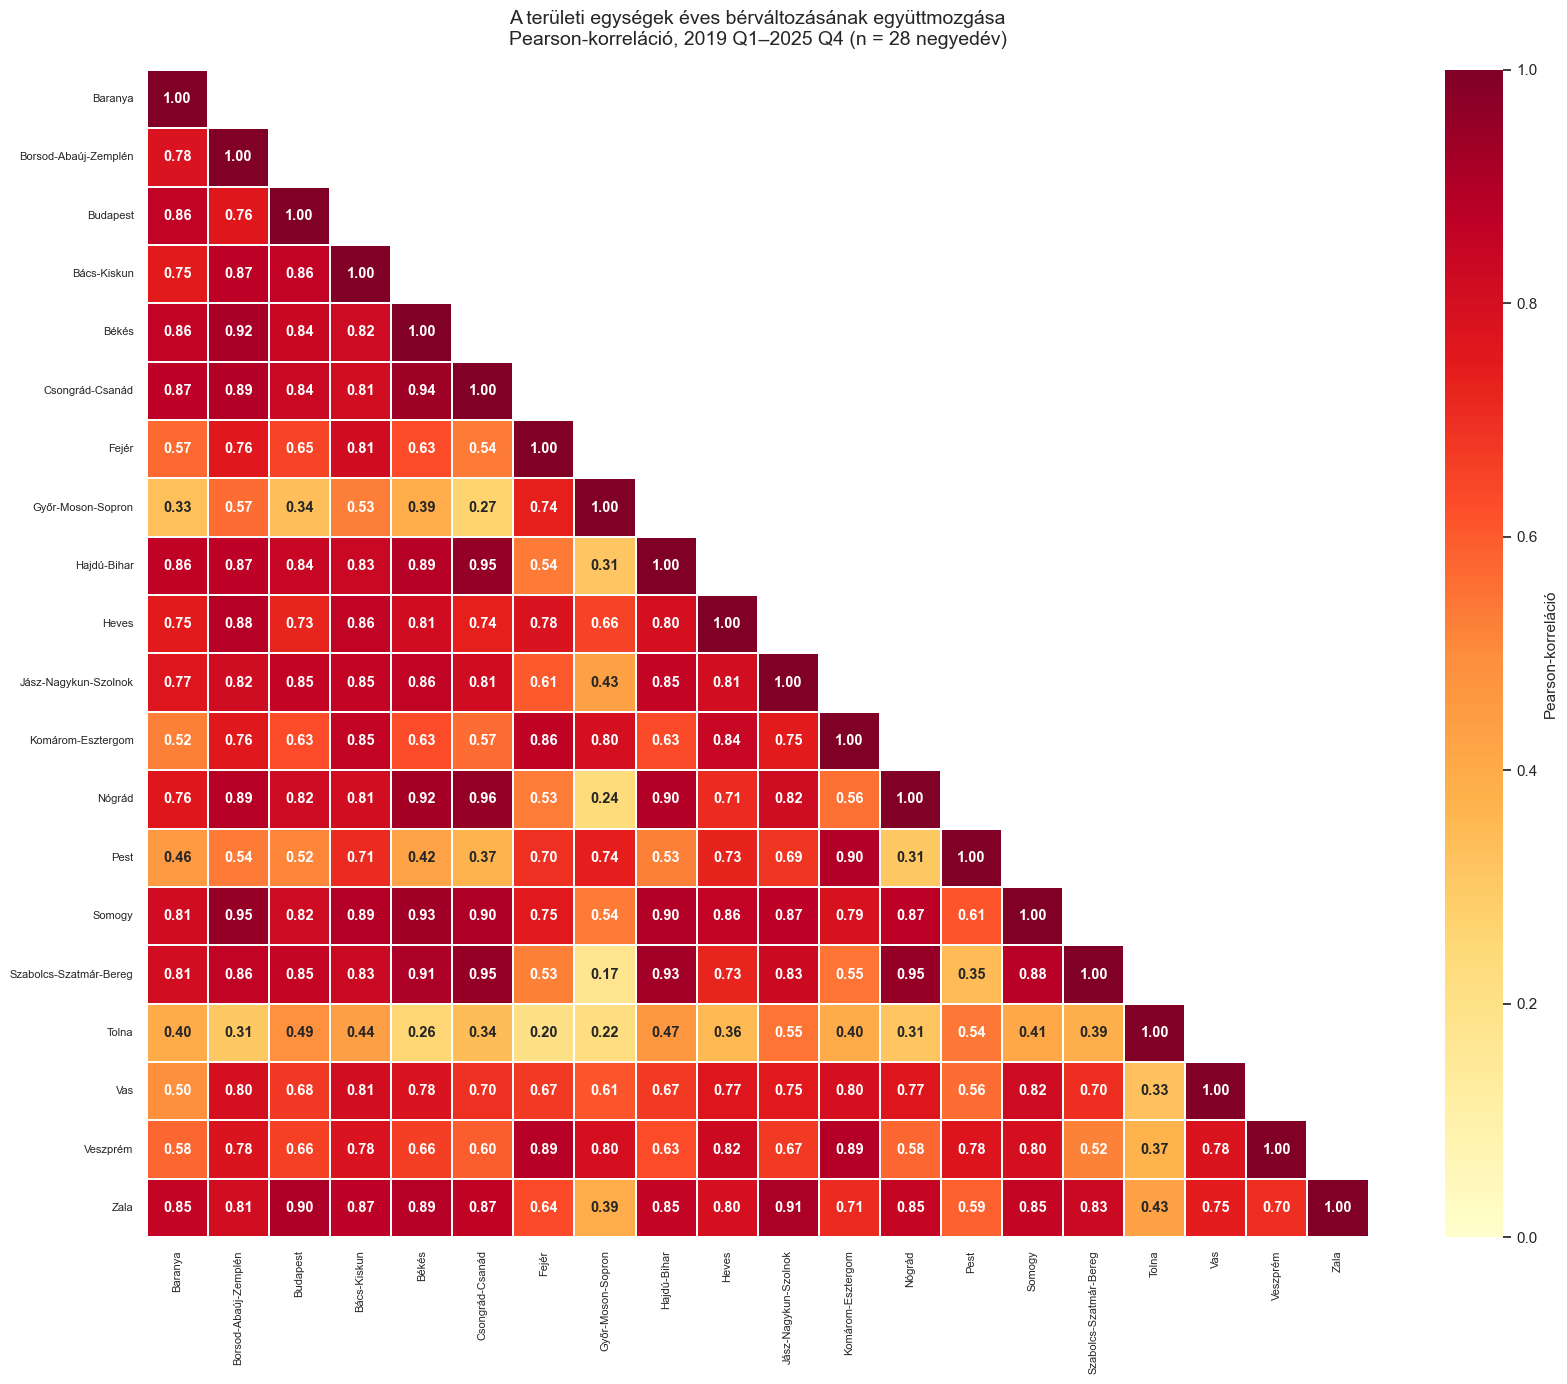

In [25]:
# TERÜLETI KORRELÁCIÓS HŐTÉRKÉP

fig, ax = plt.subplots(
    figsize=(17, 14)
)

upper_triangle_mask = np.triu(
    np.ones_like(
        region_pearson_correlation,
        dtype=bool
    ),
    k=1
)

sns.heatmap(
    region_pearson_correlation,
    mask=upper_triangle_mask,
    ax=ax,
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 10.5, "weight": "bold"},
    linewidths=0.3,
    linecolor="white",
    cbar_kws={"label": "Pearson-korreláció"},
    
)
ax.grid(False)
ax.set_title(
    "A területi egységek éves bérváltozásának együttmozgása\n"
    "Pearson-korreláció, 2019 Q1–2025 Q4 (n = 28 negyedév)",
    pad=18
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.xticks(
    rotation=90,
    fontsize=8
)

plt.yticks(
    rotation=0,
    fontsize=8
)

fig.tight_layout()

fig.savefig(
    FIGURES / "teruleti_egysegek_bernovekedesi_korrelacioja.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# TERÜLETPÁROK KORRELÁCIÓS RANGSORA

pearson_for_pairs = (
    region_pearson_correlation
    .rename_axis(
        index="Első_terület",
        columns="Második_terület"
    )
)

upper_triangle_mask = np.triu(
    np.ones(
        pearson_for_pairs.shape,
        dtype=bool
    ),
    k=1
)

regional_pair_ranking = (
    pearson_for_pairs
    .where(upper_triangle_mask)
    .stack()
    .rename("Pearson_r")
    .reset_index()
    .sort_values(
        "Pearson_r",
        ascending=False
    )
    .reset_index(drop=True)
)


print("A legerősebben együtt mozgó területpárok:")

display(
    regional_pair_ranking.head(10).round(3)
)


# Hosszú formátumú adatbázis az interaktív térképhez
pearson_long = (
    region_pearson_correlation
    .rename_axis(
        index="Kiválasztott_terület",
        columns="Összehasonlított_terület"
    )
    .stack()
    .rename("Pearson_r")
    .reset_index()
)

spearman_long = (
    region_spearman_correlation
    .rename_axis(
        index="Kiválasztott_terület",
        columns="Összehasonlított_terület"
    )
    .stack()
    .rename("Spearman_r")
    .reset_index()
)

regional_correlation_long = (
    pearson_long
    .merge(
        spearman_long,
        on=[
            "Kiválasztott_terület",
            "Összehasonlított_terület"
        ],
        how="inner",
        validate="one_to_one"
    )
)

regional_correlation_long[
    "Megfigyelések_száma"
] = regional_growth_wide.shape[0]

regional_correlation_long[
    "Abszolút_Pearson"
] = (
    regional_correlation_long["Pearson_r"]
    .abs()
)

regional_correlation_long[
    "Kapcsolat_erőssége"
] = pd.cut(
    regional_correlation_long["Abszolút_Pearson"],
    bins=[
        -0.001,
        0.30,
        0.50,
        0.70,
        1.001
    ],
    labels=[
        "Gyenge",
        "Mérsékelt",
        "Erős",
        "Nagyon erős"
    ],
    include_lowest=True
)

regional_correlation_long[
    "Kapcsolat_iránya"
] = np.select(
    [
        regional_correlation_long["Pearson_r"] > 0,
        regional_correlation_long["Pearson_r"] < 0
    ],
    [
        "Azonos irányú",
        "Ellentétes irányú"
    ],
    default="Nincs lineáris kapcsolat"
)


assert len(regional_correlation_long) == 400


# Budapest korrelációs rangsora
budapest_correlation_ranking = (
    regional_correlation_long.loc[
        (
            regional_correlation_long[
                "Kiválasztott_terület"
            ] == "Budapest"
        )
        &
        (
            regional_correlation_long[
                "Összehasonlított_terület"
            ] != "Budapest"
        )
    ]
    .sort_values(
        "Pearson_r",
        ascending=False
    )
    .reset_index(drop=True)
)


print("Budapesttel legerősebben együtt mozgó területek:")

display(
    budapest_correlation_ranking[
        [
            "Összehasonlított_terület",
            "Pearson_r",
            "Spearman_r",
            "Kapcsolat_erőssége"
        ]
    ]
    .head(10)
    .round(3)
)

A legerősebben együtt mozgó területpárok:


,Első_terület,Második_terület,Pearson_r
0,Csongrád-Csanád,Nógrád,0.957
1,Csongrád-Csanád,Hajdú-Bihar,0.954
2,Nógrád,Szabolcs-Szatmár-Bereg,0.952
3,Borsod-Abaúj-Zemplén,Somogy,0.950
4,Csongrád-Csanád,Szabolcs-Szatmár-Bereg,0.950
5,Békés,Csongrád-Csanád,0.937
6,Békés,Somogy,0.931
7,Hajdú-Bihar,Szabolcs-Szatmár-Bereg,0.926
8,Békés,Nógrád,0.923
9,Borsod-Abaúj-Zemplén,Békés,0.917


Budapesttel legerősebben együtt mozgó területek:


,Összehasonlított_terület,Pearson_r,Spearman_r,Kapcsolat_erőssége
0,Zala,0.905,0.856,Nagyon erős
1,Baranya,0.862,0.816,Nagyon erős
2,Bács-Kiskun,0.857,0.837,Nagyon erős
3,Jász-Nagykun-Szolnok,0.853,0.835,Nagyon erős
4,Szabolcs-Szatmár-Bereg,0.849,0.735,Nagyon erős
5,Hajdú-Bihar,0.844,0.784,Nagyon erős
6,Békés,0.838,0.741,Nagyon erős
7,Csongrád-Csanád,0.836,0.751,Nagyon erős
8,Somogy,0.824,0.786,Nagyon erős
9,Nógrád,0.824,0.750,Nagyon erős


In [27]:
# KORRELÁCIÓS EREDMÉNYEK MENTÉSE

region_pearson_correlation.to_csv(
    PROCESSED
    / "KSH_teruleti_YoY_bernovekedes_Pearson_matrix.csv",
    encoding="utf-8-sig"
)

region_spearman_correlation.to_csv(
    PROCESSED
    / "KSH_teruleti_YoY_bernovekedes_Spearman_matrix.csv",
    encoding="utf-8-sig"
)

regional_correlation_long.to_csv(
    PROCESSED
    / "KSH_teruleti_YoY_bernovekedes_korrelacio_long.csv",
    index=False,
    encoding="utf-8-sig"
)

regional_pair_ranking.to_csv(
    PROCESSED
    / "KSH_teruleti_YoY_bernovekedes_korrelacios_parok.csv",
    index=False,
    encoding="utf-8-sig"
)

budapest_correlation_ranking.to_csv(
    PROCESSED
    / "KSH_Budapest_YoY_bernovekedes_korrelacio.csv",
    index=False,
    encoding="utf-8-sig"
)

print("A területek közötti korrelációs eredmények elmentve.")

A területek közötti korrelációs eredmények elmentve.


## A területi egységek hierarchikus klaszterezésének előkészítése

A klaszterelemzés célja Budapest és a 19 vármegye gazdasági
helyzetük alapján történő csoportosítása.

A klaszterezéshez három, egymástól tartalmilag elkülönülő
mutatót használunk:

- a 2025. évi nominális bérszintet,
- a 2018–2025 közötti évesített nominális bérnövekedést,
- a 2018–2025 közötti átlagos munkanélküliségi rátát.

Az álláskeresői arány nem kerül be a modellbe, mert nagyon erős
kapcsolatot mutat a munkanélküliségi rátával. A foglalkoztatotti
létszámot szintén kihagyjuk a fő klaszterezésből, mert az elsősorban
a területi egységek méretét, nem pedig gazdasági teljesítményét méri.

Mivel a változók eltérő mértékegységekben szerepelnek, a
klaszterezés előtt standardizáljuk őket. A klaszterek kialakításához
Ward-féle hierarchikus klaszterezést alkalmazunk.

In [28]:
# KLASZTEREZÉSI CSOMAGOK
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

In [29]:
# KLASZTEREZÉSHEZ HASZNÁLT VÁLTOZÓK

cluster_variables = {
    "Átlagbér_2025":
        "2025. évi átlagbér",

    "Évesített_bérnövekedés_2018_2025_%":
        "Évesített bérnövekedés",

    "Átlagos_munkanélküliségi_ráta":
        "Átlagos munkanélküliségi ráta"
}

cluster_data = (
    regional_profile[
        list(cluster_variables.keys())
    ]
    .rename(
        columns=cluster_variables
    )
    .copy()
)

assert cluster_data.shape == (20, 3)

assert (
    cluster_data
    .notna()
    .all()
    .all()
)

print(
    "A klaszterezési adatbázis mérete:",
    cluster_data.shape
)

display(
    cluster_data.round(2)
)

A klaszterezési adatbázis mérete: (20, 3)


,2025. évi átlagbér,Évesített bérnövekedés,Átlagos munkanélküliségi ráta
Területi egység neve,,,
Baranya,607525.0,12.25,6.07
Borsod-Abaúj-Zemplén,571321.0,11.87,6.24
Budapest,851211.0,10.85,2.70
Bács-Kiskun,606461.0,11.63,4.04
Békés,537152.0,11.85,6.06
Csongrád-Csanád,612368.0,11.59,2.91
Fejér,680039.0,11.29,2.55
Győr-Moson-Sopron,737115.0,11.64,1.72
Hajdú-Bihar,620449.0,12.51,5.22


In [30]:
# STANDARDIZÁLÁS

cluster_scaler = StandardScaler()

cluster_scaled_array = (
    cluster_scaler
    .fit_transform(
        cluster_data
    )
)

cluster_data_scaled = pd.DataFrame(
    cluster_scaled_array,
    index=cluster_data.index,
    columns=cluster_data.columns
)

# ELLENŐRZÉS

standardization_check = pd.DataFrame(
    {
        "Átlag": (
            cluster_data_scaled
            .mean()
        ),

        "Szórás": (
            cluster_data_scaled
            .std(ddof=0)
        )
    }
)

print(
    "A standardizált változók ellenőrzése:"
)

display(
    standardization_check.round(4)
)


assert np.allclose(
    cluster_data_scaled.mean(),
    0,
    atol=1e-10
)

assert np.allclose(
    cluster_data_scaled.std(ddof=0),
    1,
    atol=1e-10
)

A standardizált változók ellenőrzése:


,Átlag,Szórás
2025. évi átlagbér,0.0,1.0
Évesített bérnövekedés,0.0,1.0
Átlagos munkanélküliségi ráta,0.0,1.0


In [31]:
# KLASZTERSZÁM VIZSGÁLATA SZILUETTMUTATÓVAL

cluster_diagnostic_rows = []

for number_of_clusters in range(2, 7):

    hierarchical_model = (
        AgglomerativeClustering(
            n_clusters=number_of_clusters,
            linkage="ward"
        )
    )

    cluster_labels = (
        hierarchical_model
        .fit_predict(
            cluster_data_scaled
        )
    )

    silhouette_value = (
        silhouette_score(
            cluster_data_scaled,
            cluster_labels,
            metric="euclidean"
        )
    )

    cluster_sizes = (
        pd.Series(cluster_labels)
        .value_counts()
    )

    cluster_diagnostic_rows.append(
        {
            "Klaszterek_száma":
                number_of_clusters,

            "Sziluettmutató":
                silhouette_value,

            "Legkisebb_klaszter":
                cluster_sizes.min(),

            "Legnagyobb_klaszter":
                cluster_sizes.max()
        }
    )

cluster_diagnostics = pd.DataFrame(
    cluster_diagnostic_rows
)


best_silhouette_k = int(
    cluster_diagnostics.loc[
        cluster_diagnostics[
            "Sziluettmutató"
        ].idxmax(),
        "Klaszterek_száma"
    ]
)

print(
    "A legmagasabb sziluettmutatóhoz tartozó "
    f"klaszterszám: {best_silhouette_k}"
)

display(
    cluster_diagnostics.round(3)
)

A legmagasabb sziluettmutatóhoz tartozó klaszterszám: 2


,Klaszterek_száma,Sziluettmutató,Legkisebb_klaszter,Legnagyobb_klaszter
0,2,0.412,9,11
1,3,0.396,1,10
2,4,0.355,1,10
3,5,0.338,1,10
4,6,0.224,1,6


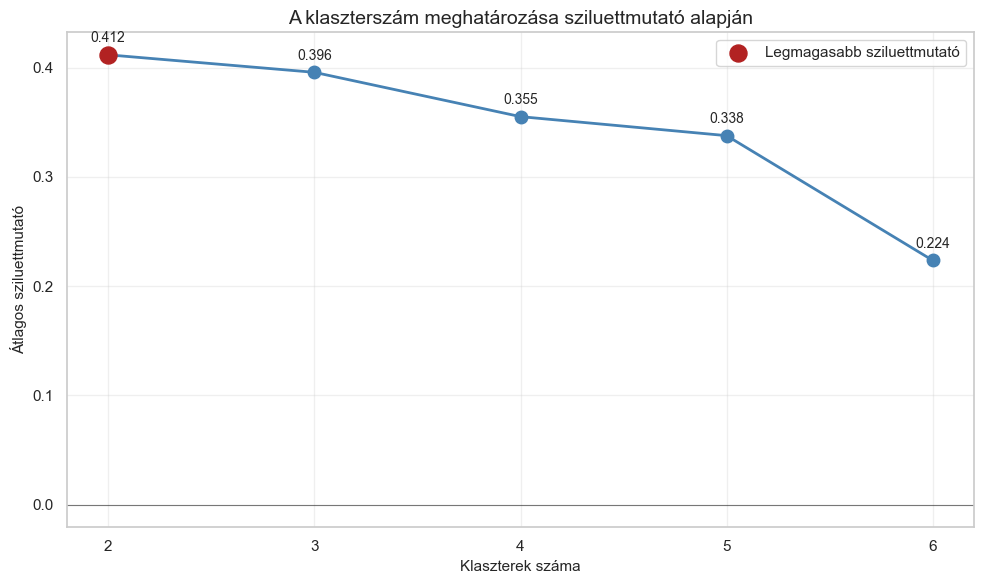

In [32]:
# SZILUETTMUTATÓ ÁBRÁZOLÁSA

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.plot(
    cluster_diagnostics[
        "Klaszterek_száma"
    ],
    cluster_diagnostics[
        "Sziluettmutató"
    ],
    marker="o",
    markersize=9,
    linewidth=2,
    color="steelblue"
)

best_row = cluster_diagnostics.loc[
    cluster_diagnostics[
        "Sziluettmutató"
    ].idxmax()
]

ax.scatter(
    best_row[
        "Klaszterek_száma"
    ],
    best_row[
        "Sziluettmutató"
    ],
    s=150,
    color="firebrick",
    zorder=3,
    label="Legmagasabb sziluettmutató"
)

for _, row in cluster_diagnostics.iterrows():

    ax.annotate(
        f"{row['Sziluettmutató']:.3f}",
        (
            row["Klaszterek_száma"],
            row["Sziluettmutató"]
        ),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
    alpha=0.5
)

ax.set_xticks(
    cluster_diagnostics[
        "Klaszterek_száma"
    ]
)

ax.set_xlabel(
    "Klaszterek száma"
)

ax.set_ylabel(
    "Átlagos sziluettmutató"
)

ax.set_title(
    "A klaszterszám meghatározása sziluettmutató alapján"
)

ax.grid(
    alpha=0.3
)

ax.legend()


plt.tight_layout()


fig.savefig(
    FIGURES
    / "klaszterszam_sziluettmutato.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

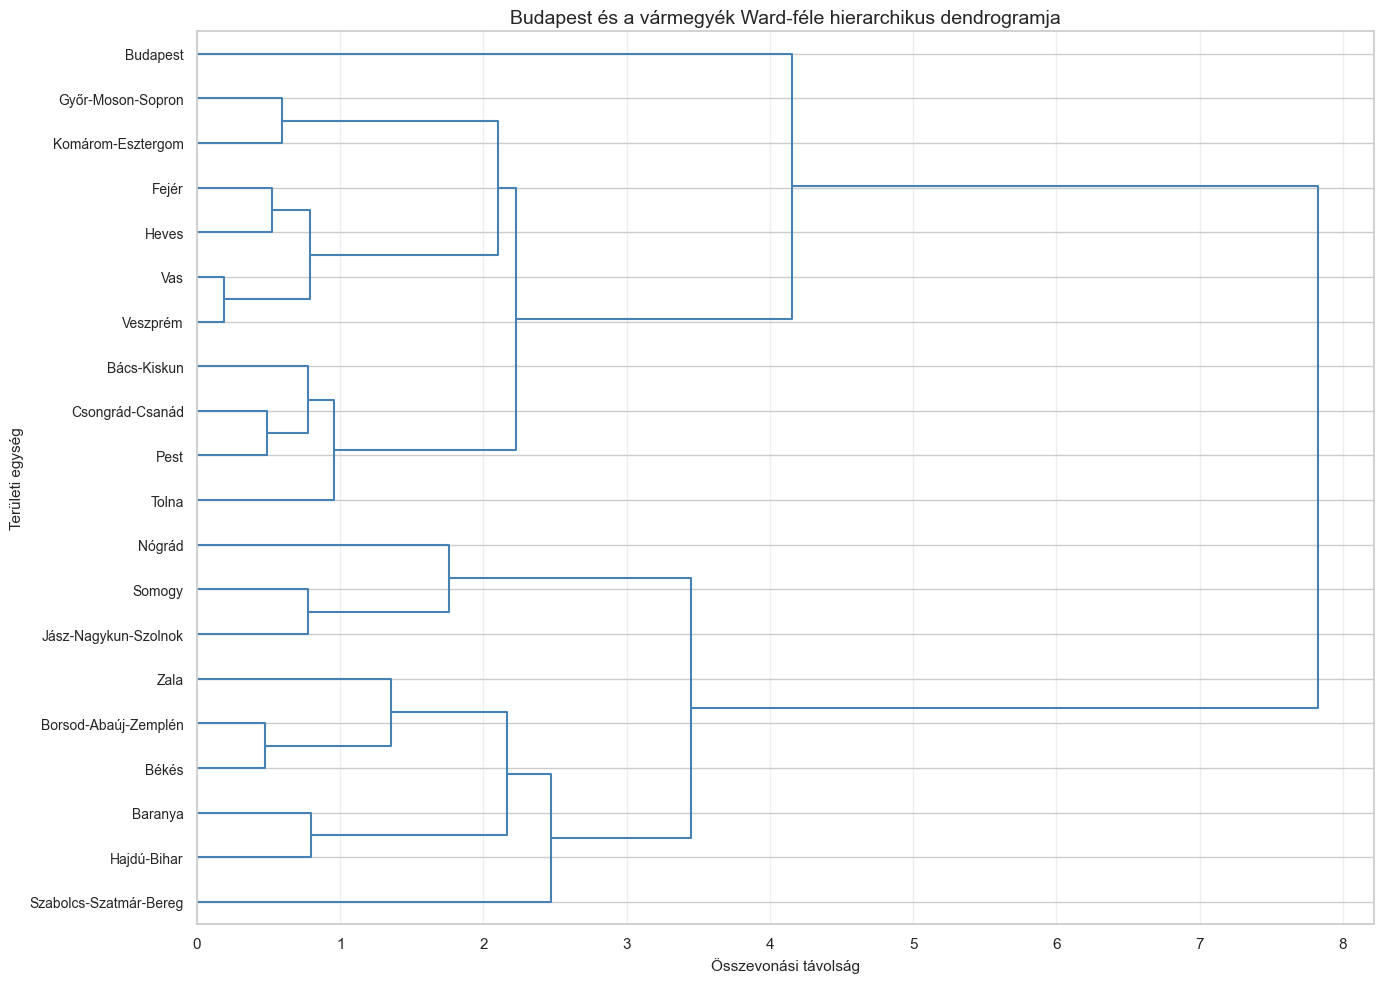

In [33]:
# WARD-FÉLE HIERARCHIKUS KLASZTEREZÉS

ward_linkage_matrix = linkage(
    cluster_data_scaled.to_numpy(),
    method="ward",
    metric="euclidean",
    optimal_ordering=True
)

fig, ax = plt.subplots(
    figsize=(14, 10)
)

dendrogram(
    ward_linkage_matrix,
    labels=cluster_data_scaled.index.tolist(),
    orientation="right",
    leaf_font_size=10,
    color_threshold=0,
    above_threshold_color="steelblue",
    ax=ax
)

ax.set_xlabel(
    "Összevonási távolság"
)

ax.set_ylabel(
    "Területi egység"
)

ax.set_title(
    "Budapest és a vármegyék Ward-féle hierarchikus dendrogramja"
)

ax.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

fig.savefig(
    FIGURES
    / "teruleti_hierarchikus_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
cluster_data.to_csv(
    PROCESSED
    / "KSH_klaszterezesi_valtozok.csv",
    encoding="utf-8-sig"
)


cluster_data_scaled.to_csv(
    PROCESSED
    / "KSH_klaszterezesi_valtozok_standardizalt.csv",
    encoding="utf-8-sig"
)


cluster_diagnostics.to_csv(
    PROCESSED
    / "KSH_klaszterszam_diagnosztika.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A klaszterezés előkészítő eredményei elmentve."
)

A klaszterezés előkészítő eredményei elmentve.


## A végleges területi klaszterek kialakítása

A vizsgált klaszterszámok közül a kétklaszteres megoldás érte el
a legmagasabb sziluettmutatót. A két csoport mérete kiegyensúlyozott,
miközben a három- vagy többklaszteres megoldásokban egyelemű
klaszterek jelentek meg.

Ezért a végleges elemzésben két klasztert alkalmazunk. A klaszterek
elnevezése nem előre meghatározott kategóriákon, hanem a kialakult
gazdasági profilok utólagos értelmezésén alapul.

In [35]:
# VÉGLEGES KÉTKLASZTERES MODELL

final_cluster_count = 2


final_cluster_model = (
    AgglomerativeClustering(
        n_clusters=final_cluster_count,
        linkage="ward"
    )
)


raw_cluster_labels = pd.Series(
    final_cluster_model.fit_predict(
        cluster_data_scaled
    ),
    index=cluster_data_scaled.index,
    name="Eredeti_klaszterkód"
)


raw_cluster_wage_means = (
    cluster_data
    .assign(
        Eredeti_klaszterkód=
            raw_cluster_labels
    )
    .groupby(
        "Eredeti_klaszterkód"
    )[
        "2025. évi átlagbér"
    ]
    .mean()
    .sort_values(
        ascending=False
    )
)


cluster_code_mapping = {
    raw_code: new_code

    for new_code, raw_code in enumerate(
        raw_cluster_wage_means.index,
        start=1
    )
}

cluster_result = (
    cluster_data
    .copy()
)

cluster_result[
    "Klaszter"
] = (
    raw_cluster_labels
    .map(
        cluster_code_mapping
    )
    .astype(int)
)

cluster_name_mapping = {
    1:
        "Magasabb bérszint / alacsonyabb munkanélküliség",

    2:
        "Alacsonyabb bérszint / magasabb munkanélküliség"
}

cluster_result[
    "Klaszter_neve"
] = (
    cluster_result[
        "Klaszter"
    ]
    .map(
        cluster_name_mapping
    )
)

assert (
    cluster_result[
        "Klaszter"
    ]
    .nunique()
    == 2
)

assert (
    cluster_result[
        "Klaszter_neve"
    ]
    .notna()
    .all()
)


print(
    "A területi egységek végleges klaszterbesorolása:"
)

display(
    cluster_result
    .sort_values(
        [
            "Klaszter",
            "2025. évi átlagbér"
        ],
        ascending=[
            True,
            False
        ]
    )
    .round(2)
)

A területi egységek végleges klaszterbesorolása:


,2025. évi átlagbér,Évesített bérnövekedés,Átlagos munkanélküliségi ráta,Klaszter,Klaszter_neve
Területi egység neve,,,,,
Budapest,851211.0,10.85,2.70,1,Magasabb bérszint / alacsonyabb munkanélküliség
Győr-Moson-Sopron,737115.0,11.64,1.72,1,Magasabb bérszint / alacsonyabb munkanélküliség
Komárom-Esztergom,696992.0,11.57,2.12,1,Magasabb bérszint / alacsonyabb munkanélküliség
Fejér,680039.0,11.29,2.55,1,Magasabb bérszint / alacsonyabb munkanélküliség
Tolna,663112.0,11.76,4.10,1,Magasabb bérszint / alacsonyabb munkanélküliség
Heves,647641.0,11.35,3.05,1,Magasabb bérszint / alacsonyabb munkanélküliség
Pest,646120.0,11.65,2.74,1,Magasabb bérszint / alacsonyabb munkanélküliség
Vas,636925.0,11.19,2.40,1,Magasabb bérszint / alacsonyabb munkanélküliség
Veszprém,627027.0,11.23,2.20,1,Magasabb bérszint / alacsonyabb munkanélküliség


In [36]:
# KLASZTERPROFILOK EREDETI MÉRTÉKEGYSÉGBEN

cluster_profile = (
    cluster_result
    .groupby(
        [
            "Klaszter",
            "Klaszter_neve"
        ]
    )
    .agg(
        Területi_egységek_száma=(
            "Klaszter",
            "size"
        ),

        Átlagbér_2025_Ft=(
            "2025. évi átlagbér",
            "mean"
        ),

        Évesített_bérnövekedés_százalék=(
            "Évesített bérnövekedés",
            "mean"
        ),

        Átlagos_munkanélküliségi_ráta_százalék=(
            "Átlagos munkanélküliségi ráta",
            "mean"
        )
    )
    .reset_index()
)

print(
    "A végleges klaszterek gazdasági profiljai:"
)

display(
    cluster_profile.style.format(
        {
            "Átlagbér_2025_Ft":
                "{:,.0f} Ft",

            "Évesített_bérnövekedés_százalék":
                "{:.2f}%",

            "Átlagos_munkanélküliségi_ráta_százalék":
                "{:.2f}%"
        }
    )
)

A végleges klaszterek gazdasági profiljai:


,Klaszter,Klaszter_neve,Területi_egységek_száma,Átlagbér_2025_Ft,Évesített_bérnövekedés_százalék,Átlagos_munkanélküliségi_ráta_százalék
0,1,Magasabb bérszint / alacsonyabb munkanélküliség,11,"673,183 Ft",11.43%,2.78%
1,2,Alacsonyabb bérszint / magasabb munkanélküliség,9,"570,153 Ft",11.91%,6.24%


In [37]:
# STANDARDIZÁLT KLASZTERPROFILOK

cluster_profile_scaled = (
    cluster_data_scaled
    .assign(
        Klaszter=
            cluster_result[
                "Klaszter"
            ]
    )
    .groupby(
        "Klaszter"
    )
    .mean()
    .sort_index()
)

cluster_profile_scaled.index = [
    cluster_name_mapping[
        cluster_code
    ]

    for cluster_code
    in cluster_profile_scaled.index
]

cluster_profile_scaled.index.name = (
    "Klaszter"
)

display(
    cluster_profile_scaled.round(2)
)

,2025. évi átlagbér,Évesített bérnövekedés,Átlagos munkanélküliségi ráta
Klaszter,,,
Magasabb bérszint / alacsonyabb munkanélküliség,0.63,-0.53,-0.76
Alacsonyabb bérszint / magasabb munkanélküliség,-0.76,0.65,0.93


In [38]:
# FŐKOMPONENS-ELEMZÉS A KLASZTEREK VIZUALIZÁLÁSÁHOZ

from sklearn.decomposition import PCA

pca_model = PCA(
    n_components=2
)

pca_coordinates = (
    pca_model
    .fit_transform(
        cluster_data_scaled
    )
)

pca_result = pd.DataFrame(
    pca_coordinates,
    index=cluster_data_scaled.index,
    columns=[
        "PC1",
        "PC2"
    ]
)


pca_result[
    "Klaszter"
] = (
    cluster_result[
        "Klaszter"
    ]
)


pca_result[
    "Klaszter_neve"
] = (
    cluster_result[
        "Klaszter_neve"
    ]
)

explained_variance = (
    pca_model
    .explained_variance_ratio_
    * 100
)

print(
    "Az első két főkomponens által magyarázott variancia:",
    f"{explained_variance.sum():.2f}%"
)

Az első két főkomponens által magyarázott variancia: 90.54%


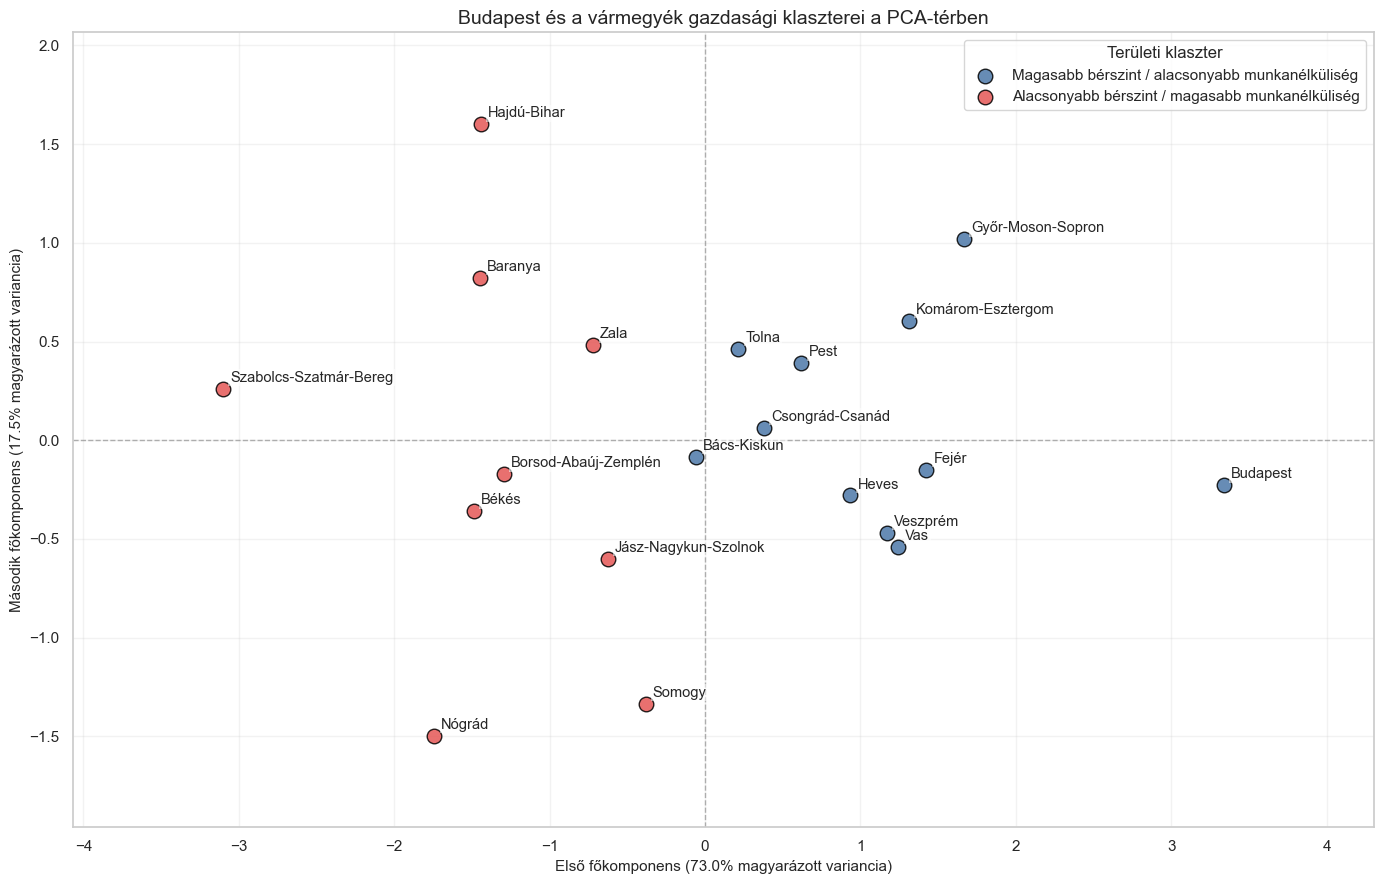

In [39]:
# A TERÜLETI KLASZTEREK PCA-ÁBRÁJA

cluster_colors = {
    1: "#4C78A8",
    2: "#E45756"
}

fig, ax = plt.subplots(
    figsize=(14, 9)
)

for cluster_code in sorted(
    pca_result[
        "Klaszter"
    ].unique()
):

    cluster_plot_data = (
        pca_result[
            pca_result[
                "Klaszter"
            ]
            == cluster_code
        ]
    )


    ax.scatter(
        cluster_plot_data[
            "PC1"
        ],
        cluster_plot_data[
            "PC2"
        ],
        s=110,
        alpha=0.85,
        edgecolor="black",
        color=cluster_colors[
            cluster_code
        ],
        label=cluster_name_mapping[
            cluster_code
        ]
    )

    for region_name, row in (
        cluster_plot_data
        .iterrows()
    ):

        ax.annotate(
            region_name,
            (
                row["PC1"],
                row["PC2"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=10.5,
            bbox={
                "facecolor": "white",
                "alpha": 0.55,
                "edgecolor": "none",
                "pad": 1
            }
        )

ax.axhline(
    0,
    color="grey",
    linewidth=1,
    linestyle="--",
    alpha=0.6
)

ax.axvline(
    0,
    color="grey",
    linewidth=1,
    linestyle="--",
    alpha=0.6
)

ax.set_xlabel(
    "Első főkomponens "
    f"({explained_variance[0]:.1f}% magyarázott variancia)"
)

ax.set_ylabel(
    "Második főkomponens "
    f"({explained_variance[1]:.1f}% magyarázott variancia)"
)

ax.set_title(
    "Budapest és a vármegyék gazdasági klaszterei a PCA-térben"
)

ax.legend(
    title="Területi klaszter"
)

ax.grid(
    alpha=0.25
)

ax.margins(
    x=0.15,
    y=0.15
)

plt.tight_layout()

fig.savefig(
    FIGURES
    / "teruleti_klaszterek_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
# KLASZTEREK HOZZÁKAPCSOLÁSA A TELJES TERÜLETI PROFILHOZ

regional_profile_with_clusters = (
    regional_profile
    .join(
        cluster_result[
            [
                "Klaszter",
                "Klaszter_neve"
            ]
        ]
    )
)

assert (
    regional_profile_with_clusters[
        "Klaszter"
    ]
    .notna()
    .all()
)

regional_profile_with_clusters.to_csv(
    PROCESSED
    / "KSH_teruleti_profilok_klaszterekkel.csv",
    encoding="utf-8-sig"
)

cluster_profile.to_csv(
    PROCESSED
    / "KSH_klaszterprofilok.csv",
    index=False,
    encoding="utf-8-sig"
)

cluster_profile_scaled.to_csv(
    PROCESSED
    / "KSH_standardizalt_klaszterprofilok.csv",
    encoding="utf-8-sig"
)

pca_result.to_csv(
    PROCESSED
    / "KSH_teruleti_klaszterek_PCA.csv",
    encoding="utf-8-sig"
)

print(
    "A végleges klaszterbesorolások, klaszterprofilok "
    "és PCA-koordináták elmentve."
)

A végleges klaszterbesorolások, klaszterprofilok és PCA-koordináták elmentve.


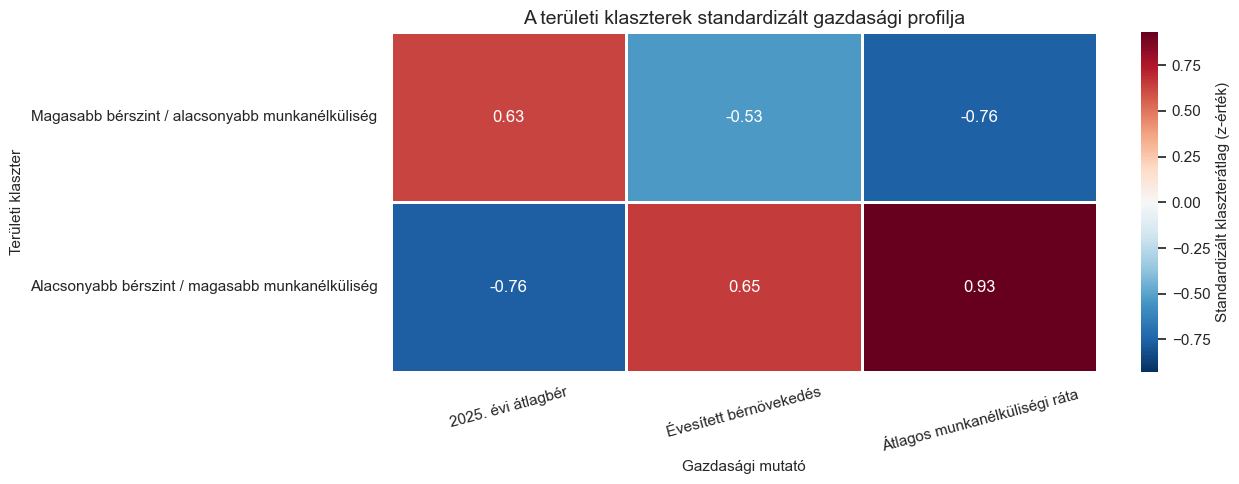

In [41]:
# STANDARDIZÁLT KLASZTERPROFIL-HŐTÉRKÉP

heatmap_limit = float(
    np.abs(
        cluster_profile_scaled.to_numpy()
    ).max()
)


fig, ax = plt.subplots(
    figsize=(13, 5)
)


sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-heatmap_limit,
    vmax=heatmap_limit,
    linewidths=0.8,
    cbar_kws={
        "label":
            "Standardizált klaszterátlag (z-érték)"
    },
    ax=ax
)


ax.set_xlabel(
    "Gazdasági mutató"
)

ax.set_ylabel(
    "Területi klaszter"
)

ax.set_title(
    "A területi klaszterek standardizált gazdasági profilja"
)

ax.tick_params(
    axis="x",
    rotation=15
)

ax.tick_params(
    axis="y",
    rotation=0
)


plt.tight_layout()


fig.savefig(
    FIGURES
    / "teruleti_klaszterprofil_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
# A FŐKOMPONENSEK ÉRTELMEZÉSÉHEZ HASZNÁLT VÁLTOZÓSÚLYOK

pca_loadings = pd.DataFrame(
    pca_model.components_.T,
    index=cluster_data_scaled.columns,
    columns=[
        "PC1",
        "PC2"
    ]
)


pca_loadings[
    "PC1_abszolút_súly"
] = (
    pca_loadings[
        "PC1"
    ].abs()
)


pca_loadings[
    "PC2_abszolút_súly"
] = (
    pca_loadings[
        "PC2"
    ].abs()
)


print(
    "A változók főkomponensekhez tartozó súlyai:"
)


display(
    pca_loadings.round(3)
)

A változók főkomponensekhez tartozó súlyai:


,PC1,PC2,PC1_abszolút_súly,PC2_abszolút_súly
2025. évi átlagbér,0.598,0.376,0.598,0.376
Évesített bérnövekedés,-0.534,0.846,0.534,0.846
Átlagos munkanélküliségi ráta,-0.598,-0.379,0.598,0.379


## A területi klaszterek időbeli gazdasági pályái

A következő elemzés azt vizsgálja, hogyan alakult a két klaszter
átlagos bérszintje és munkanélküliségi rátája 2018 és 2025 között.

A klaszterenkénti átlagok számításakor minden területi egység azonos
súlyt kap. Így Budapest vagy a nagyobb népességű vármegyék nem
befolyásolják aránytalanul a klaszterátlagokat.

A klaszterek a teljes vizsgált időszak összesített gazdasági profiljai
alapján jöttek létre, ezért az elemzés leíró jellegű, nem pedig időn
kívüli előrejelzési vizsgálat.

In [43]:
# KLASZTEREK HOZZÁKAPCSOLÁSA A NEGYEDÉVES PANELADATOKHOZ

cluster_lookup = (
    cluster_result[
        [
            "Klaszter",
            "Klaszter_neve"
        ]
    ]
    .reset_index()
)


df_cluster_time = (
    df_eda
    .merge(
        cluster_lookup,
        on="Területi egység neve",
        how="left",
        validate="many_to_one"
    )
)


assert len(
    df_cluster_time
) == len(
    df_eda
)


assert (
    df_cluster_time[
        [
            "Klaszter",
            "Klaszter_neve"
        ]
    ]
    .notna()
    .all()
    .all()
)


quarterly_cluster_sizes = (
    df_cluster_time
    .groupby(
        [
            "Dátum",
            "Klaszter"
        ]
    )[
        "Területi egység neve"
    ]
    .nunique()
    .unstack(
        "Klaszter"
    )
)


expected_cluster_sizes = (
    cluster_result[
        "Klaszter"
    ]
    .value_counts()
    .sort_index()
)


for cluster_code in expected_cluster_sizes.index:

    assert (
        quarterly_cluster_sizes[
            cluster_code
        ]
        ==
        expected_cluster_sizes[
            cluster_code
        ]
    ).all()


print(
    "A negyedéves panel klaszterbesorolása megfelelő."
)

display(
    quarterly_cluster_sizes.head()
)

A negyedéves panel klaszterbesorolása megfelelő.


Klaszter,1,2
Dátum,,
2018-01-01,11,9
2018-04-01,11,9
2018-07-01,11,9
2018-10-01,11,9
2019-01-01,11,9


In [44]:
# NEGYEDÉVES KLASZTERÁTLAGOK

cluster_quarterly_trends = (
    df_cluster_time
    .groupby(
        [
            "Dátum",
            "Klaszter",
            "Klaszter_neve"
        ],
        as_index=False
    )
    .agg(
        Területi_átlagbér=(
            "Bruttó_átlagkereset_HUF",
            "mean"
        ),

        Bérszórás=(
            "Bruttó_átlagkereset_HUF",
            "std"
        ),

        Átlagos_munkanélküliségi_ráta=(
            "Munkanélküliségi_ráta_%",
            "mean"
        ),

        Munkanélküliségi_szórás=(
            "Munkanélküliségi_ráta_%",
            "std"
        ),

        Átlagos_YoY_bérnövekedés=(
            "Bér_Növekedés_YoY_%",
            "mean"
        ),

        Területi_egységek_száma=(
            "Területi egység neve",
            "nunique"
        )
    )
    .sort_values(
        [
            "Klaszter",
            "Dátum"
        ]
    )
    .reset_index(
        drop=True
    )
)

In [45]:
# BÉRINDEX: 2018 ELSŐ NEGYEDÉVE = 100

cluster_quarterly_trends[
    "Bázisidőszaki_átlagbér"
] = (
    cluster_quarterly_trends
    .groupby(
        "Klaszter"
    )[
        "Területi_átlagbér"
    ]
    .transform(
        "first"
    )
)


cluster_quarterly_trends[
    "Bérindex_2018Q1_100"
] = (
    cluster_quarterly_trends[
        "Területi_átlagbér"
    ]
    /
    cluster_quarterly_trends[
        "Bázisidőszaki_átlagbér"
    ]
    * 100
)


first_index_values = (
    cluster_quarterly_trends
    .groupby(
        "Klaszter"
    )[
        "Bérindex_2018Q1_100"
    ]
    .first()
)


assert np.allclose(
    first_index_values,
    100
)

display(
    cluster_quarterly_trends
    .head(8)
    .round(
        {
            "Területi_átlagbér": 2,
            "Bérszórás": 2,
            "Átlagos_munkanélküliségi_ráta": 2,
            "Munkanélküliségi_szórás": 2,
            "Átlagos_YoY_bérnövekedés": 2,
            "Bázisidőszaki_átlagbér": 2,
            "Bérindex_2018Q1_100": 2
        }
    )
)

,Dátum,Klaszter,Klaszter_neve,Területi_átlagbér,Bérszórás,Átlagos_munkanélküliségi_ráta,Munkanélküliségi_szórás,Átlagos_YoY_bérnövekedés,Területi_egységek_száma,Bázisidőszaki_átlagbér,Bérindex_2018Q1_100
0,2018-01-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,300549.91,36056.97,2.27,0.83,NaN,11,300549.91,100.00
1,2018-04-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,318219.18,39806.74,2.19,0.59,NaN,11,300549.91,105.88
2,2018-07-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,311124.00,32887.13,2.44,0.62,NaN,11,300549.91,103.52
3,2018-10-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,333503.64,39494.69,2.25,0.57,NaN,11,300549.91,110.96
4,2019-01-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,336684.64,41088.49,2.29,0.72,12.00,11,300549.91,112.02
5,2019-04-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,354604.27,42972.91,2.04,0.69,11.47,11,300549.91,117.99
6,2019-07-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,349025.45,38223.45,2.22,0.81,12.15,11,300549.91,116.13
7,2019-10-01,1,Magasabb bérszint / alacsonyabb munkanélküliség,374850.73,47173.16,2.19,0.85,12.33,11,300549.91,124.72


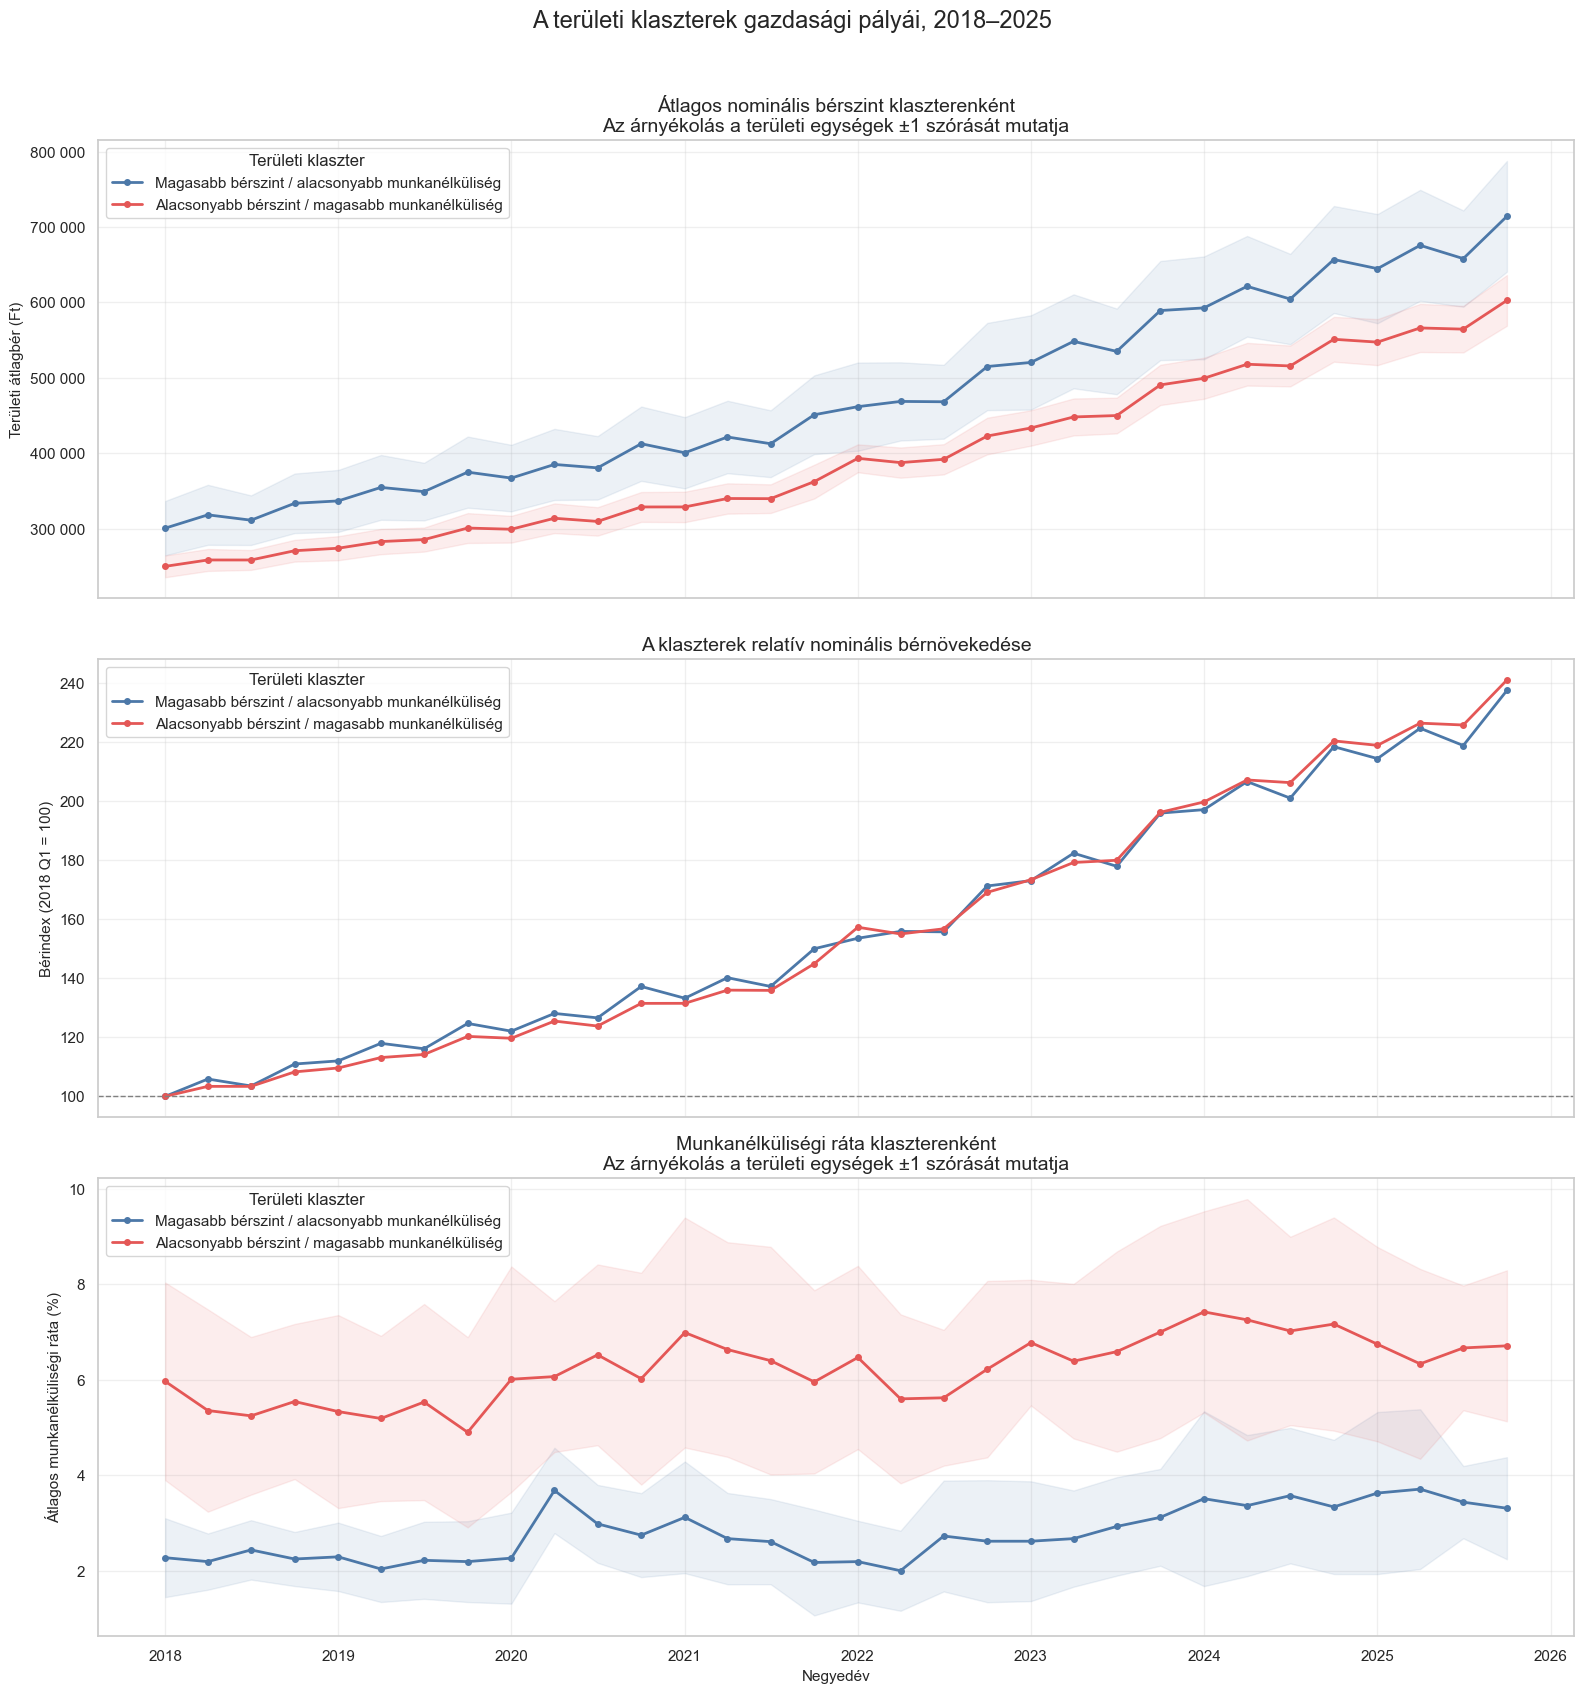

In [46]:
# A KLASZTEREK IDŐBELI GAZDASÁGI PÁLYÁI

import matplotlib.dates as mdates


fig, axes = plt.subplots(
    3,
    1,
    figsize=(16, 17),
    sharex=True
)


for cluster_code in sorted(
    cluster_quarterly_trends[
        "Klaszter"
    ].unique()
):

    plot_data = (
        cluster_quarterly_trends[
            cluster_quarterly_trends[
                "Klaszter"
            ]
            == cluster_code
        ]
        .sort_values(
            "Dátum"
        )
    )


    dates = (
        plot_data[
            "Dátum"
        ].to_numpy()
    )

    wage_mean = (
        plot_data[
            "Területi_átlagbér"
        ].to_numpy(
            dtype=float
        )
    )

    wage_std = (
        plot_data[
            "Bérszórás"
        ].to_numpy(
            dtype=float
        )
    )

    unemployment_mean = (
        plot_data[
            "Átlagos_munkanélküliségi_ráta"
        ].to_numpy(
            dtype=float
        )
    )

    unemployment_std = (
        plot_data[
            "Munkanélküliségi_szórás"
        ].to_numpy(
            dtype=float
        )
    )


    # Nominális bérszint

    axes[0].plot(
        dates,
        wage_mean,
        marker="o",
        markersize=4,
        linewidth=2,
        color=cluster_colors[
            cluster_code
        ],
        label=cluster_name_mapping[
            cluster_code
        ]
    )

    axes[0].fill_between(
        dates,
        wage_mean - wage_std,
        wage_mean + wage_std,
        color=cluster_colors[
            cluster_code
        ],
        alpha=0.10
    )


    # Bérindex

    axes[1].plot(
        dates,
        plot_data[
            "Bérindex_2018Q1_100"
        ],
        marker="o",
        markersize=4,
        linewidth=2,
        color=cluster_colors[
            cluster_code
        ],
        label=cluster_name_mapping[
            cluster_code
        ]
    )


    # Munkanélküliségi ráta

    axes[2].plot(
        dates,
        unemployment_mean,
        marker="o",
        markersize=4,
        linewidth=2,
        color=cluster_colors[
            cluster_code
        ],
        label=cluster_name_mapping[
            cluster_code
        ]
    )

    axes[2].fill_between(
        dates,
        np.maximum(
            unemployment_mean
            -
            unemployment_std,
            0
        ),
        unemployment_mean
        +
        unemployment_std,
        color=cluster_colors[
            cluster_code
        ],
        alpha=0.10
    )


axes[0].yaxis.set_major_formatter(
    FuncFormatter(
        thousands_formatter
    )
)

axes[0].set_ylabel(
    "Területi átlagbér (Ft)"
)

axes[0].set_title(
    "Átlagos nominális bérszint klaszterenként\n"
    "Az árnyékolás a területi egységek ±1 szórását mutatja"
)


axes[1].axhline(
    100,
    color="grey",
    linestyle="--",
    linewidth=1
)

axes[1].set_ylabel(
    "Bérindex (2018 Q1 = 100)"
)

axes[1].set_title(
    "A klaszterek relatív nominális bérnövekedése"
)


axes[2].set_ylabel(
    "Átlagos munkanélküliségi ráta (%)"
)

axes[2].set_xlabel(
    "Negyedév"
)

axes[2].set_title(
    "Munkanélküliségi ráta klaszterenként\n"
    "Az árnyékolás a területi egységek ±1 szórását mutatja"
)


for ax in axes:

    ax.grid(
        alpha=0.3
    )

    ax.legend(
        title="Területi klaszter",
        loc="best"
    )


axes[2].xaxis.set_major_locator(
    mdates.YearLocator()
)

axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y"
    )
)


fig.suptitle(
    "A területi klaszterek gazdasági pályái, 2018–2025",
    fontsize=17,
    y=0.995
)


plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.98
    ]
)


fig.savefig(
    FIGURES
    / "teruleti_klaszterek_idobeli_palyai.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
pca_loadings.to_csv(
    PROCESSED
    / "KSH_PCA_valtozosulyok.csv",
    encoding="utf-8-sig"
)


df_cluster_time.to_csv(
    PROCESSED
    / "KSH_panel_klaszterekkel.csv",
    index=False,
    encoding="utf-8-sig"
)


cluster_quarterly_trends.to_csv(
    PROCESSED
    / "KSH_klaszterek_negyedeves_trendjei.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A PCA-változósúlyok és a klaszterek "
    "időbeli eredményei elmentve."
)

A PCA-változósúlyok és a klaszterek időbeli eredményei elmentve.


## A klaszterek közötti különbségek időbeli változása

A klaszterátlagok vizsgálata mellett fontos annak elemzése is,
hogy a két csoport közötti gazdasági különbségek csökkentek vagy
növekedtek-e a vizsgált időszak során.

Az abszolút nominális bérkülönbség mellett relatív bérkülönbséget
is számítunk. Az abszolút különbség az általános béremelkedés miatt
akkor is növekedhet, ha a két klaszter növekedési üteme hasonló.
A relatív különbség ezért alkalmasabb a felzárkózási tendencia
vizsgálatára.

In [48]:
# KLASZTERÁTLAGOK SZÉLES FORMÁTUMBAN

wage_trends_wide = (
    cluster_quarterly_trends
    .pivot(
        index="Dátum",
        columns="Klaszter",
        values="Területi_átlagbér"
    )
)


unemployment_trends_wide = (
    cluster_quarterly_trends
    .pivot(
        index="Dátum",
        columns="Klaszter",
        values="Átlagos_munkanélküliségi_ráta"
    )
)


assert {
    1,
    2
}.issubset(
    wage_trends_wide.columns
)


assert (
    wage_trends_wide
    .notna()
    .all()
    .all()
)


assert (
    unemployment_trends_wide
    .notna()
    .all()
    .all()
)

In [49]:
# A KÉT KLASZTER KÖZÖTTI KÜLÖNBSÉGEK

cluster_gap_trends = pd.DataFrame(
    {
        "Dátum":
            wage_trends_wide.index,

        # Pozitív érték: az 1. klaszter átlagbére magasabb
        "Abszolút_bérkülönbség_Ft":
            (
                wage_trends_wide[1]
                -
                wage_trends_wide[2]
            ).to_numpy(),

        # Az 1. klaszter bérelőnye a 2. klaszterhez képest
        "Relatív_bérkülönbség_%":
            (
                (
                    wage_trends_wide[1]
                    /
                    wage_trends_wide[2]
                )
                -
                1
            )
            .mul(100)
            .to_numpy(),

        # Pozitív érték: a 2. klaszterben magasabb a munkanélküliség
        "Munkanélküliségi_különbség_százalékpont":
            (
                unemployment_trends_wide[2]
                -
                unemployment_trends_wide[1]
            ).to_numpy()
    }
)


display(
    cluster_gap_trends
    .head()
    .round(2)
)

C:\Users\wldbe\AppData\Local\Temp\ipykernel_3216\17272335.py:44: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,Dátum,Abszolút_bérkülönbség_Ft,Relatív_bérkülönbség_%,Munkanélküliségi_különbség_százalékpont
0,2018-01-01,50660.02,20.27,3.69
1,2018-04-01,59869.74,23.17,3.16
2,2018-07-01,52790.67,20.44,2.81
3,2018-10-01,62888.30,23.24,3.30
4,2019-01-01,62747.19,22.91,3.04


In [50]:
# A KLASZTERKÜLÖNBSÉGEK KEZDŐ- ÉS VÉGÉRTÉKEI

first_gap_row = (
    cluster_gap_trends
    .iloc[0]
)


last_gap_row = (
    cluster_gap_trends
    .iloc[-1]
)


cluster_gap_summary = pd.DataFrame(
    {
        "Mutató": [
            "Abszolút bérkülönbség (Ft)",
            "Relatív bérkülönbség (%)",
            "Munkanélküliségi különbség (százalékpont)"
        ],

        "2018_Q1": [
            first_gap_row[
                "Abszolút_bérkülönbség_Ft"
            ],

            first_gap_row[
                "Relatív_bérkülönbség_%"
            ],

            first_gap_row[
                "Munkanélküliségi_különbség_százalékpont"
            ]
        ],

        "2025_Q4": [
            last_gap_row[
                "Abszolút_bérkülönbség_Ft"
            ],

            last_gap_row[
                "Relatív_bérkülönbség_%"
            ],

            last_gap_row[
                "Munkanélküliségi_különbség_százalékpont"
            ]
        ]
    }
)


cluster_gap_summary[
    "Változás"
] = (
    cluster_gap_summary[
        "2025_Q4"
    ]
    -
    cluster_gap_summary[
        "2018_Q1"
    ]
)


display(
    cluster_gap_summary.round(2)
)

,Mutató,2018_Q1,2025_Q4,Változás
0,Abszolút bérkülönbség (Ft),50660.02,111547.11,60887.09
1,Relatív bérkülönbség (%),20.27,18.51,-1.76
2,Munkanélküliségi különbség (százalékpont),3.69,3.40,-0.29


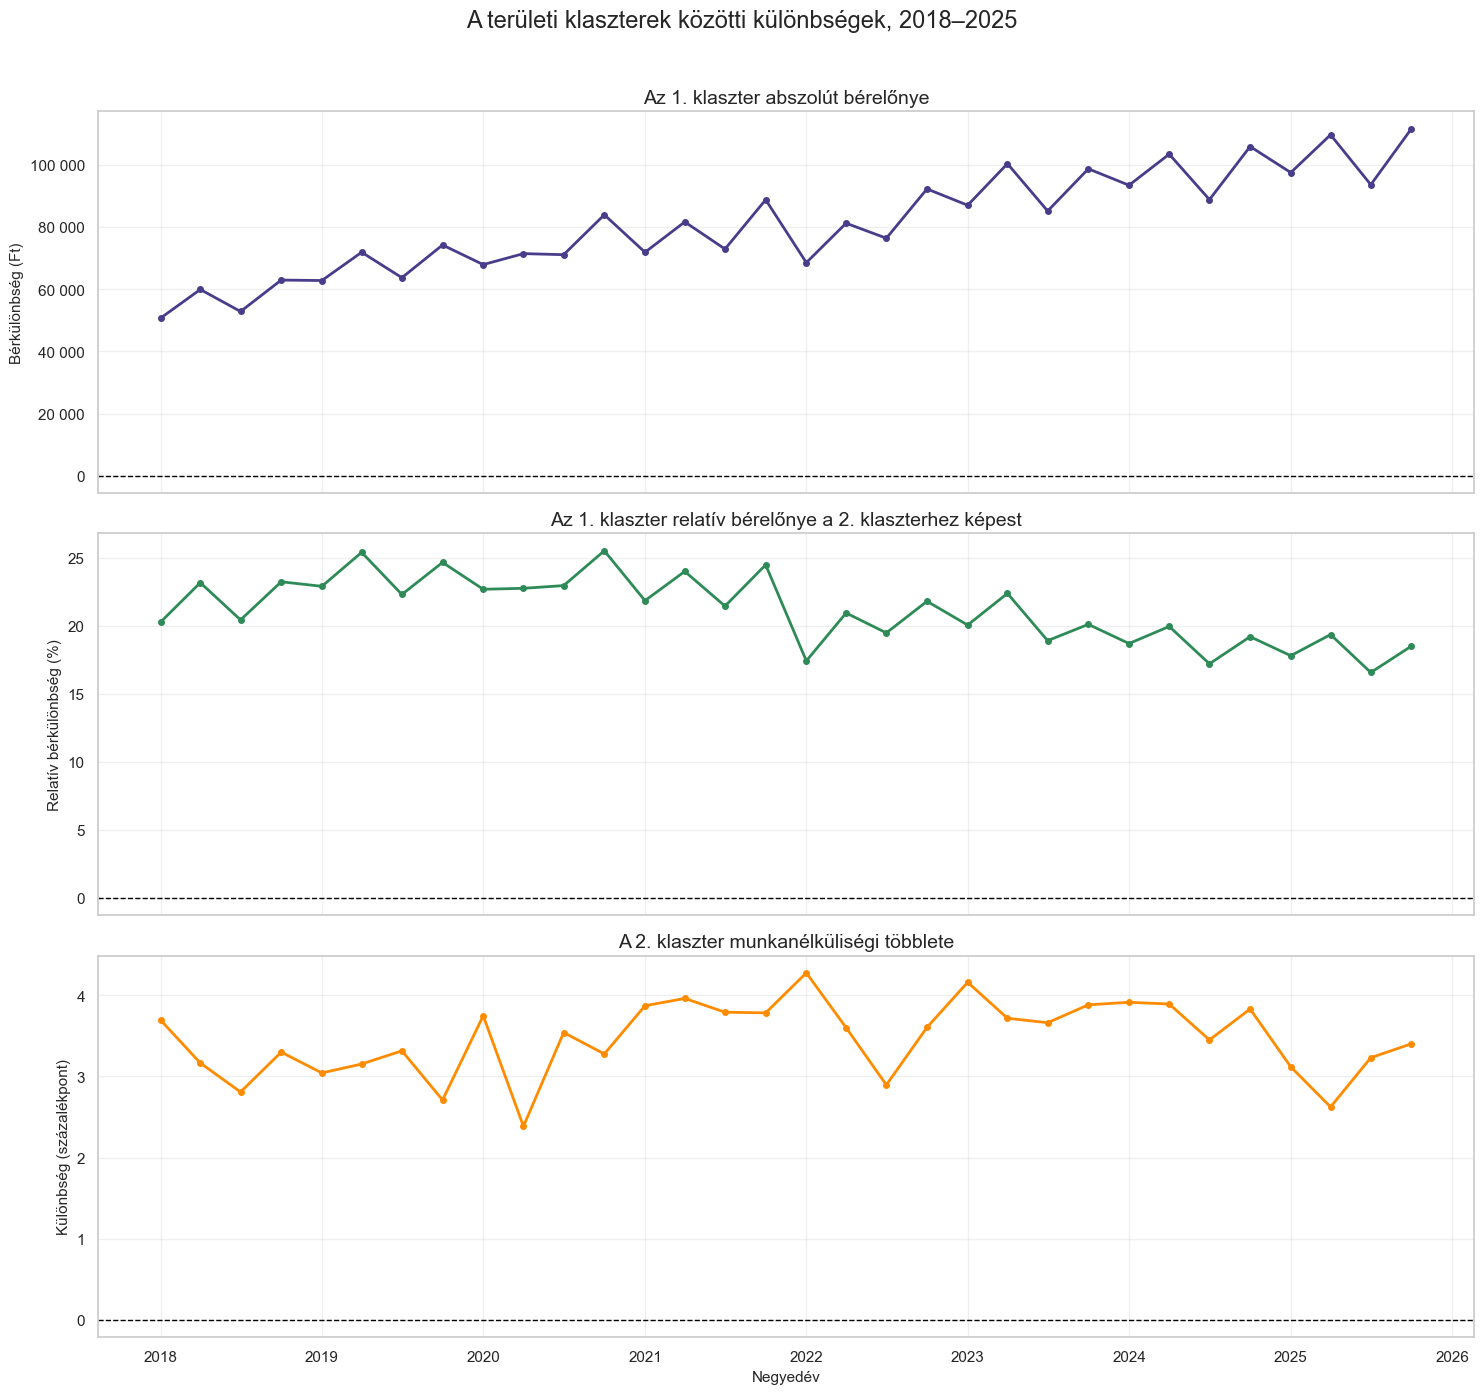

In [51]:
# A KLASZTEREK KÖZÖTTI KÜLÖNBSÉGEK ÁBRÁZOLÁSA

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 14),
    sharex=True
)


# ABSZOLÚT BÉRKÜLÖNBSÉG

axes[0].plot(
    cluster_gap_trends[
        "Dátum"
    ],
    cluster_gap_trends[
        "Abszolút_bérkülönbség_Ft"
    ],
    marker="o",
    markersize=4,
    linewidth=2,
    color="darkslateblue"
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].yaxis.set_major_formatter(
    FuncFormatter(
        thousands_formatter
    )
)

axes[0].set_ylabel(
    "Bérkülönbség (Ft)"
)

axes[0].set_title(
    "Az 1. klaszter abszolút bérelőnye"
)


# RELATÍV BÉRKÜLÖNBSÉG

axes[1].plot(
    cluster_gap_trends[
        "Dátum"
    ],
    cluster_gap_trends[
        "Relatív_bérkülönbség_%"
    ],
    marker="o",
    markersize=4,
    linewidth=2,
    color="seagreen"
)

axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_ylabel(
    "Relatív bérkülönbség (%)"
)

axes[1].set_title(
    "Az 1. klaszter relatív bérelőnye a 2. klaszterhez képest"
)


# MUNKANÉLKÜLISÉGI KÜLÖNBSÉG

axes[2].plot(
    cluster_gap_trends[
        "Dátum"
    ],
    cluster_gap_trends[
        "Munkanélküliségi_különbség_százalékpont"
    ],
    marker="o",
    markersize=4,
    linewidth=2,
    color="darkorange"
)

axes[2].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[2].set_ylabel(
    "Különbség (százalékpont)"
)

axes[2].set_xlabel(
    "Negyedév"
)

axes[2].set_title(
    "A 2. klaszter munkanélküliségi többlete"
)


axes[2].xaxis.set_major_locator(
    mdates.YearLocator()
)

axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y"
    )
)


for ax in axes:

    ax.grid(
        alpha=0.3
    )


fig.suptitle(
    "A területi klaszterek közötti különbségek, 2018–2025",
    fontsize=17,
    y=0.995
)


plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.98
    ]
)


fig.savefig(
    FIGURES
    / "teruleti_klaszterkulonbsegek_idosora.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## A klaszterbesorolás robusztussági ellenőrzése

A Ward-féle hierarchikus klaszterezéssel kapott csoportok
robusztusságát KMeans klaszterezéssel ellenőrizzük.

Mindkét módszer ugyanazokat a standardizált gazdasági mutatókat és
két klasztert használ. A két besorolás hasonlóságát az Adjusted Rand
Index, a normalizált kölcsönös információ és a területi egységek
azonos besorolási aránya alapján értékeljük.

A magas egyezés arra utal, hogy a kapott klaszterstruktúra nem
kizárólag egyetlen klaszterezési algoritmus sajátosságából ered.

In [52]:
# KMEANS ROBUSZTUSSÁGI MODELL

from sklearn.cluster import KMeans

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)


kmeans_model = KMeans(
    n_clusters=2,
    n_init=50,
    random_state=42
)


raw_kmeans_labels = pd.Series(
    kmeans_model.fit_predict(
        cluster_data_scaled
    ),
    index=cluster_data_scaled.index,
    name="KMeans_eredeti_kód"
)

In [53]:
# KMEANS-KLASZTERKÓDOK EGYSÉGESÍTÉSE

kmeans_wage_means = (
    cluster_data
    .assign(
        KMeans_eredeti_kód=
            raw_kmeans_labels
    )
    .groupby(
        "KMeans_eredeti_kód"
    )[
        "2025. évi átlagbér"
    ]
    .mean()
    .sort_values(
        ascending=False
    )
)


kmeans_code_mapping = {
    raw_code: new_code

    for new_code, raw_code in enumerate(
        kmeans_wage_means.index,
        start=1
    )
}


kmeans_cluster_labels = (
    raw_kmeans_labels
    .map(
        kmeans_code_mapping
    )
    .astype(int)
)

In [54]:
# HIERARCHIKUS ÉS KMEANS-BESOROLÁS ÖSSZEHASONLÍTÁSA

cluster_robustness_membership = pd.DataFrame(
    {
        "Ward_klaszter":
            cluster_result[
                "Klaszter"
            ],

        "KMeans_klaszter":
            kmeans_cluster_labels
    }
)


cluster_robustness_membership[
    "Egyező_besorolás"
] = (
    cluster_robustness_membership[
        "Ward_klaszter"
    ]
    ==
    cluster_robustness_membership[
        "KMeans_klaszter"
    ]
)


hierarchical_silhouette = (
    silhouette_score(
        cluster_data_scaled,
        cluster_result[
            "Klaszter"
        ]
    )
)


kmeans_silhouette = (
    silhouette_score(
        cluster_data_scaled,
        kmeans_cluster_labels
    )
)


adjusted_rand_value = (
    adjusted_rand_score(
        cluster_result[
            "Klaszter"
        ],
        kmeans_cluster_labels
    )
)


normalized_mutual_information = (
    normalized_mutual_info_score(
        cluster_result[
            "Klaszter"
        ],
        kmeans_cluster_labels
    )
)


membership_agreement = (
    cluster_robustness_membership[
        "Egyező_besorolás"
    ]
    .mean()
)


cluster_robustness_summary = pd.DataFrame(
    {
        "Mutató": [
            "Ward sziluettmutató",
            "KMeans sziluettmutató",
            "Adjusted Rand Index",
            "Normalizált kölcsönös információ",
            "Egyező besorolások aránya"
        ],

        "Érték": [
            hierarchical_silhouette,
            kmeans_silhouette,
            adjusted_rand_value,
            normalized_mutual_information,
            membership_agreement
        ]
    }
)


display(
    cluster_robustness_summary.round(3)
)

,Mutató,Érték
0,Ward sziluettmutató,0.412
1,KMeans sziluettmutató,0.412
2,Adjusted Rand Index,1.000
3,Normalizált kölcsönös információ,1.000
4,Egyező besorolások aránya,1.000


In [55]:
# KLASZTERBESOROLÁSI KERESZTTÁBLA

cluster_agreement_table = pd.crosstab(
    cluster_robustness_membership[
        "Ward_klaszter"
    ],
    cluster_robustness_membership[
        "KMeans_klaszter"
    ],
    rownames=[
        "Ward-klaszter"
    ],
    colnames=[
        "KMeans-klaszter"
    ],
    margins=True
)


display(
    cluster_agreement_table
)


different_assignments = (
    cluster_robustness_membership[
        ~cluster_robustness_membership[
            "Egyező_besorolás"
        ]
    ]
)


if different_assignments.empty:

    print(
        "A Ward- és KMeans-módszer minden területi "
        "egységet azonos klaszterbe sorolt."
    )

else:

    print(
        "Eltérően besorolt területi egységek:"
    )

    display(
        different_assignments
    )

KMeans-klaszter,1,2,All
Ward-klaszter,,,
1,11,0,11
2,0,9,9
All,11,9,20


A Ward- és KMeans-módszer minden területi egységet azonos klaszterbe sorolt.


In [56]:
cluster_gap_trends.to_csv(
    PROCESSED
    / "KSH_klaszterkulonbsegek_idosora.csv",
    index=False,
    encoding="utf-8-sig"
)


cluster_gap_summary.to_csv(
    PROCESSED
    / "KSH_klaszterkulonbsegek_osszefoglalo.csv",
    index=False,
    encoding="utf-8-sig"
)


cluster_robustness_membership.to_csv(
    PROCESSED
    / "KSH_klaszter_robusztussagi_besorolasok.csv",
    encoding="utf-8-sig"
)


cluster_robustness_summary.to_csv(
    PROCESSED
    / "KSH_klaszter_robusztussagi_mutatok.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A klaszterkülönbségek és a robusztussági "
    "vizsgálat eredményei elmentve."
)

A klaszterkülönbségek és a robusztussági vizsgálat eredményei elmentve.


## Összegzés

A feltáró elemzés a 2018 és 2025 közötti, 20 területi egységet
és 32 negyedévet tartalmazó kiegyensúlyozott paneladatbázisra épült.

Az eredmények a nominális bruttó átlagkeresetek jelentős emelkedését,
valamint tartós területi bér- és munkaerőpiaci különbségeket mutattak.
A magasabb bérszint jellemzően alacsonyabb munkanélküliségi rátával
társult. A bérszint és az évesített bérnövekedés negatív kapcsolata
mérsékelt felzárkózási tendenciára utalt, de önmagában nem bizonyít
gazdasági konvergenciát.

A standardizált gazdasági mutatókon végzett Ward-féle hierarchikus
klaszterezés két területi csoportot azonosított. Az első klaszter
11, jellemzően magasabb bérszintű és alacsonyabb munkanélküliségű
területi egységet tartalmazott. A második klaszterbe 9, alacsonyabb
bérszintű és magasabb munkanélküliségű területi egység került.

A második klaszter évesített nominális bérnövekedése kissé magasabb
volt. Ennek megfelelően az első klaszter relatív bérelőnye
20,27%-ról 18,51%-ra csökkent. Az abszolút nominális bérkülönbség
ugyanakkor 50 660 forintról 111 547 forintra emelkedett. A
munkanélküliségi különbség csak mérsékelten, 3,69 százalékpontról
3,40 százalékpontra csökkent.

A Ward-féle hierarchikus klaszterezés és a KMeans-modell minden
területi egységet azonos csoportba sorolt. Az Adjusted Rand Index
és a normalizált kölcsönös információ értéke egyaránt 1,000 volt.
Ez azt mutatja, hogy a kialakult kétklaszteres struktúra nem kizárólag
egy adott klaszterezési algoritmus sajátosságából ered.

Az eredmények leíró jellegűek. A nominális bérek változása nem
azonos a reálbérek változásával, a kimutatott összefüggések pedig
nem értelmezhetők automatikusan ok-okozati kapcsolatként.